# Uber / Ride-Sharing Operations Analytics — New York City, 2014–2015

**Author:** Jatin Gohel &nbsp;|&nbsp; **Tools:** Python (pandas, NumPy, Matplotlib, Seaborn), SQL (PostgreSQL), Excel, Power BI

## 1. Project introduction

In 2014–2015 Uber was growing fast in New York City. Every Uber pickup is reported to the NYC Taxi & Limousine Commission
(TLC), and FiveThirtyEight obtained these records through a Freedom of Information Law (FOIL) request:
**18,804,806 pickups** — 4,534,327 from April–September 2014 and 14,270,479 from January–June 2015 — plus daily
vehicle counts for Uber's bases and TLC summary tables for taxis and other for-hire vehicles.

This notebook analyses the data the way an operations team would: **when** demand happens (hours, weekdays, holidays),
**where** it happens (boroughs, zones, airports), **how fast it grows**, **how many vehicles** were active and how many
trips each one did, and **how Uber compared with yellow taxis, Lyft and other car services**.

Workflow: raw files → understanding → data-quality checks → cleaning → feature engineering → EDA → KPIs → trends →
segments → findings → recommendations. The notebook also exports the analysis-ready tables used by SQL, Excel and Power BI.

> Every number is calculated from the raw files in `data/raw/`. Re-running the notebook reproduces all tables and charts.

## 2. Business problem

An operations team at a ride-hailing company has to put **the right number of drivers in the right place at the right
time**. Too few drivers means long waits and lost trips; too many means idle drivers and wasted incentives.

| Area | Question |
|---|---|
| Demand over time | How many trips per day and month? How fast is demand growing (month over month, year over year)? |
| Demand patterns | Which hours and weekdays are busiest? How different are weekends, late nights and holidays? |
| Geography | Which boroughs, zones and airports generate trips? Is demand spreading beyond Manhattan? |
| Supply | How many vehicles were active, and how many trips did each vehicle do per day? |
| Bases | How are trips split between Uber's dispatching bases, and how did that change? |
| Market | How big was Uber compared with yellow taxis, Lyft and other car services? |

**What this data cannot answer (so it is not invented):**
* **Revenue, fares, surge pricing, profit** — the files contain no prices.
* **Trip distance, duration, drop-off location** — only the pickup is recorded.
* **Cancellations, wait times / ETAs, ratings** — not in the data.
* **True driver utilization** (share of online time spent with a passenger) and driver earnings — there are no driver
  hours. The FOIL file gives *active vehicles* per base and day, so **trips per active vehicle per day** is used as a
  productivity proxy and is labelled as such.
* **Customers and retention** — riders are not identified.

## 3. Dataset & source

| Item | Detail |
|---|---|
| Dataset | **Uber TLC FOIL response** — Uber pickups in New York City (Apr–Sep 2014, Jan–Jun 2015) and related TLC files |
| Original source | NYC Taxi & Limousine Commission (TLC), released to FiveThirtyEight under a Freedom of Information Law request (files received Aug–Sep 2015) |
| Publisher | FiveThirtyEight — GitHub repository `fivethirtyeight/uber-tlc-foil-response` (commit `63bb878`). The same data is republished on Kaggle as *Uber Pickups in New York City*. |
| How obtained | Kaggle could not be reached from the build environment, so the files were downloaded from FiveThirtyEight's GitHub repository (the original publisher) and verified with SHA-256 checksums (`data/raw/SHA256SUMS.txt`). |
| Retrieved | 22 Oct 2026 |
| License / terms | The source repository has no license file. The data are public records released by the TLC; FiveThirtyEight's data repository states that its data sets are available under CC BY 4.0 unless otherwise noted. Credit: NYC TLC and FiveThirtyEight. |

| File | Content | Used for |
|---|---|---|
| `uber-raw-data-apr14.csv` … `sep14.csv` | One row per pickup: date/time, latitude, longitude, base (Apr–Sep 2014) | Demand 2014, pickup map |
| `uber-raw-data-janjune-15.csv.zip` | One row per pickup: dispatching base, date/time, affiliated base, taxi-zone id (Jan–Jun 2015) | Demand 2015, boroughs, zones |
| `taxi-zone-lookup.csv` | Taxi-zone id → borough and zone name | Geography |
| `Uber-Jan-Feb-FOIL.csv` | Per base and day: active vehicles and trips (Jan–Feb 2015) | Supply / productivity |
| `Aggregate FHV Data.xlsx` | TLC summary: daily trips of Uber, Lyft, yellow taxis, green taxis and 8 car services (Jul–Sep 2014) | Market context, validation |
| `other-FHV-data-jan-aug-2015.csv` | TLC base report: daily trips and vehicles of 334 other for-hire bases (Jan–Aug 2015) | Data-quality check only — its coverage changes from month to month (section 10), so it is not used for market share |

The 7 large trip files are not stored in the GitHub repository (size limits); `scripts/download_data.py` downloads them
from the pinned commit and checks every SHA-256 checksum. Not used: the trip-level files of 10 other car services in the
source repository (out of scope).

## 4. Import libraries & chart style

In [1]:
from pathlib import Path
import json
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
import seaborn as sns
from pandas.tseries.holiday import USFederalHolidayCalendar

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, CLEAN, REPORTS = ROOT / "data" / "raw", ROOT / "data" / "cleaned", ROOT / "reports"
FIG = REPORTS / "figures"
for folder in (CLEAN, FIG):
    folder.mkdir(parents=True, exist_ok=True)
print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)

pandas 3.0.5 | numpy 2.5.3 | seaborn 0.13.2


In [2]:
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE, LIGHT_GRAY = PALETTE[0], PALETTE[1], "#c9c7bf"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": False, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.prop_cycle": plt.cycler(color=PALETTE), "lines.linewidth": 2,
    "font.family": "sans-serif", "font.sans-serif": ["Inter", "Segoe UI", "Arial", "DejaVu Sans"],
    "font.size": 10, "legend.frameon": False, "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
})
sns.set_palette(PALETTE)


def compact(x, pos=None):
    """Compact count label: 1.2M, 350K, 90."""
    def trim(v, d):
        return f"{v:.{d}f}".rstrip("0").rstrip(".")
    if abs(x) >= 1e6:
        return f"{trim(x / 1e6, 2)}M"
    if abs(x) >= 1e3:
        return f"{trim(x / 1e3, 1)}K"
    return f"{x:,.0f}"


def pct_axis(ax, axis="y", decimals=0):
    fmt = mticker.PercentFormatter(1.0, decimals=decimals)
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)


def save(fig, name):
    fig.savefig(FIG / f"{name}.png")
    plt.show()


WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

## 5. Load data

The 2014 data comes as six monthly CSV files; the 2015 data is one zipped CSV (14 million rows). Two small files use old
Mac line endings (carriage return only) and the base report has five title lines above its header, so they need
explicit read options.

In [3]:
BASE_NAMES = {"B02512": "Unter", "B02598": "Hinter", "B02617": "Weiter", "B02682": "Schmecken",
              "B02764": "Danach-NY", "B02765": "Grun", "B02835": "Dreist", "B02836": "Drinnen"}   # from the source README
FILES_2014 = [f"uber-raw-data-{m}14.csv" for m in ("apr", "may", "jun", "jul", "aug", "sep")]
FILE_2015 = "uber-raw-data-janjune-15.csv.zip"
missing = [f for f in FILES_2014 + [FILE_2015] if not (RAW / f).exists()]
if missing:
    raise FileNotFoundError("Large raw files are missing - run `python scripts/download_data.py` first: " + ", ".join(missing))

raw14 = pd.concat([pd.read_csv(RAW / f, dtype={"Base": "category"}).assign(source_file=f) for f in FILES_2014],
                  ignore_index=True)
with zipfile.ZipFile(RAW / FILE_2015) as z:
    print("Files inside the 2015 zip:", z.namelist())
    with z.open("uber-raw-data-janjune-15.csv") as f:
        raw15 = pd.read_csv(f, dtype={"Dispatching_base_num": "category", "Affiliated_base_num": "category",
                                      "locationID": "int16"})
zones_raw = pd.read_csv(RAW / "taxi-zone-lookup.csv", lineterminator="\r")     # CR-only line endings
foil_raw = pd.read_csv(RAW / "Uber-Jan-Feb-FOIL.csv")
tlc_raw = pd.read_excel(RAW / "Aggregate FHV Data.xlsx", sheet_name="Trips Per Day")
fhv_raw = pd.read_csv(RAW / "other-FHV-data-jan-aug-2015.csv", skiprows=5, lineterminator="\r", dtype=str)
print("All files loaded.")

Files inside the 2015 zip: ['uber-raw-data-janjune-15.csv', '__MACOSX/', '__MACOSX/._uber-raw-data-janjune-15.csv']


All files loaded.


## 6. Dataset shape

In [4]:
datasets = {"Uber pickups 2014 (6 files)": raw14, "Uber pickups 2015": raw15, "Taxi zones": zones_raw,
            "FOIL daily base stats (Jan-Feb 2015)": foil_raw, "TLC daily trips summary (Jul-Sep 2014)": tlc_raw,
            "Other FHV base report (Jan-Aug 2015)": fhv_raw}
shape = pd.DataFrame({"rows": {k: len(v) for k, v in datasets.items()},
                      "columns": {k: v.shape[1] for k, v in datasets.items()}})
display(shape)
print("Rows per 2014 file:")
raw14["source_file"].value_counts().reindex(FILES_2014)

,rows,columns
Uber pickups 2014 (6 files),4534327,5
Uber pickups 2015,14270479,4
Taxi zones,265,3
FOIL daily base stats (Jan-Feb 2015),354,4
TLC daily trips summary (Jul-Sep 2014),92,13
Other FHV base report (Jan-Aug 2015),26182,7


Rows per 2014 file:


source_file
uber-raw-data-apr14.csv     564516
uber-raw-data-may14.csv     652435
uber-raw-data-jun14.csv     663844
uber-raw-data-jul14.csv     796121
uber-raw-data-aug14.csv     829275
uber-raw-data-sep14.csv    1028136
Name: count, dtype: int64

## 7. Data types

In [5]:
for name, df in datasets.items():
    print(f"--- {name}")
    print(df.dtypes.to_string(), "\n")

--- Uber pickups 2014 (6 files)
Date/Time           str
Lat             float64
Lon             float64
Base           category
source_file         str 

--- Uber pickups 2015
Dispatching_base_num    category
Pickup_date                  str
Affiliated_base_num     category
locationID                 int16 

--- Taxi zones
LocationID    int64
Borough         str
Zone            str 

--- FOIL daily base stats (Jan-Feb 2015)
dispatching_base_number      str
date                         str
active_vehicles            int64
trips                      int64 

--- TLC daily trips summary (Jul-Sep 2014)
Date            datetime64[us]
American                 int64
Carmel                   int64
Dial 7                   int64
Diplo                    int64
Firstclass               int64
Highclass                int64
Prestige                 int64
Skyline                  int64
Lyft                     int64
Uber                     int64
Yellow Taxis             int64
Green Taxis            

In [6]:
display(raw14.head(3), raw15.head(3), zones_raw.head(3), foil_raw.head(3), tlc_raw.head(3), fhv_raw.head(3))

,Date/Time,Lat,Lon,Base,source_file
0,4/1/2014 0:11:00,40.77,-73.95,B02512,uber-raw-data-apr14.csv
1,4/1/2014 0:17:00,40.73,-74.03,B02512,uber-raw-data-apr14.csv
2,4/1/2014 0:21:00,40.73,-73.99,B02512,uber-raw-data-apr14.csv


,Dispatching_base_num,Pickup_date,Affiliated_base_num,locationID
0,B02617,2015-05-17 09:47:00,B02617,141
1,B02617,2015-05-17 09:47:00,B02617,65
2,B02617,2015-05-17 09:47:00,B02617,100


,LocationID,Borough,Zone
0,1,EWR,Newark Airport
1,2,Queens,Jamaica Bay
2,3,Bronx,Allerton/Pelham Gardens


,dispatching_base_number,date,active_vehicles,trips
0,B02512,1/1/2015,190,1132
1,B02765,1/1/2015,225,1765
2,B02764,1/1/2015,3427,29421


,Date,American,Carmel,Dial 7,Diplo,Firstclass,Highclass,Prestige,Skyline,Lyft,Uber,Yellow Taxis,Green Taxis
0,2014-07-01,921,2871,2233,1046,1744,1368,3345,1668,0,21228,440655,38167
1,2014-07-02,1028,2965,2409,1275,2228,1661,3533,1691,0,26480,434416,42472
2,2014-07-03,1068,3361,2520,1200,2121,1599,3649,1157,0,21597,412980,46046


,Unnamed: 0,Base Number,Base Name,Unnamed: 3,Pick Up Date,Number of Trips,Number of Vehicles
0,NaN,B00013,LOVE CORP CAR INC,NaN,01/01/2015,26,17
1,NaN,B00014,NY ONE CORP CAR INC,NaN,01/01/2015,45,24
2,NaN,B00029,COMMUNITY CAR SVC CORP,NaN,01/01/2015,731,36


**Notes:** dates are stored as text in two different formats (`4/1/2014 0:11:00` and `2015-05-17 09:47:00`); the 2015
file has no coordinates, only a taxi-zone id (`locationID`); the base report keeps numbers as text with thousands
separators (`" 1,137 "`) and has empty helper columns.

## 8. Missing-value analysis

In [7]:
rows = []
for name, df in datasets.items():
    for col, n in df.isna().sum().items():
        if n:
            rows.append({"dataset": name, "column": col, "missing": n, "missing_%": n / len(df) * 100})
missing_report = pd.DataFrame(rows)
missing_report

,dataset,column,missing,missing_%
0,Uber pickups 2015,Affiliated_base_num,162195,1.14
1,Other FHV base report (Jan-Aug 2015),Unnamed: 0,26182,100.00
2,Other FHV base report (Jan-Aug 2015),Base Number,1,0.00
3,Other FHV base report (Jan-Aug 2015),Base Name,1,0.00
4,Other FHV base report (Jan-Aug 2015),Unnamed: 3,26182,100.00
5,Other FHV base report (Jan-Aug 2015),Pick Up Date,1,0.00
6,Other FHV base report (Jan-Aug 2015),Number of Trips,1,0.00
7,Other FHV base report (Jan-Aug 2015),Number of Vehicles,1,0.00


* **2015 `Affiliated_base_num`: 162,195 missing (1.14%)** — the dispatching base is always
  present, so these trips are kept and the affiliated base is labelled "Unknown".
* The base report's missing values are its empty helper columns and the blank line at the end of the file (removed in cleaning).
* The trip files have no other missing values.

## 9. Duplicate analysis

Pickup times are recorded to the minute, and 2015 locations only to the taxi zone, so two different trips can produce
identical rows (same base, minute and place). Before removing anything, the duplicates are tested against the TLC's own
totals.

In [8]:
ts14 = pd.to_datetime(raw14["Date/Time"], format="%m/%d/%Y %H:%M:%S")
ts15 = pd.to_datetime(raw15["Pickup_date"], format="%Y-%m-%d %H:%M:%S")
dup14 = raw14.duplicated(subset=["Date/Time", "Lat", "Lon", "Base"])
dup15 = raw15.duplicated()
n_dup14, n_dup15 = int(dup14.sum()), int(dup15.sum())
print(f"2014 identical rows: {dup14.sum():,} ({dup14.mean():.2%})")
print(f"2015 identical rows: {dup15.sum():,} ({dup15.mean():.2%})")

# Test 1 - the TLC summary workbook reports Uber's trips per day for Jul-Sep 2014
tlc_uber = tlc_raw.set_index(pd.to_datetime(tlc_raw["Date"]))["Uber"]
day14 = ts14.dt.normalize()
test1 = pd.DataFrame({"tlc_uber_trips": tlc_uber,
                      "rows_incl_duplicates": day14.value_counts().reindex(tlc_uber.index),
                      "rows_excl_duplicates": day14[~dup14].value_counts().reindex(tlc_uber.index)})
print("Days where the row count equals the TLC total -",
      "keeping duplicates:", (test1.rows_incl_duplicates == test1.tlc_uber_trips).sum(), "of", len(test1),
      "| removing duplicates:", (test1.rows_excl_duplicates == test1.tlc_uber_trips).sum())
test1.head()

2014 identical rows: 82,581 (1.82%)
2015 identical rows: 898,225 (6.29%)


Days where the row count equals the TLC total - keeping duplicates: 92 of 92 | removing duplicates: 0


,tlc_uber_trips,rows_incl_duplicates,rows_excl_duplicates
Date,,,
2014-07-01,21228,21228,20875
2014-07-02,26480,26480,26040
2014-07-03,21597,21597,21208
2014-07-04,14148,14148,13921
2014-07-05,10890,10890,10693


In [9]:
# Test 2 - the FOIL file reports trips per base and day for Jan-Feb 2015
in_foil_period = ts15 < "2015-03-01"
foil_total = foil_raw["trips"].sum()
incl = int(in_foil_period.sum())
excl = int((in_foil_period & ~dup15).sum())
print(f"FOIL trips Jan-Feb 2015: {foil_total:,}")
print(f"Pickup rows incl. duplicates: {incl:,} ({incl / foil_total - 1:+.1%} vs FOIL)")
print(f"Pickup rows excl. duplicates: {excl:,} ({excl / foil_total - 1:+.1%} vs FOIL)")

# Test 3 - timestamp precision and identical rows by month (2015)
month15 = ts15.dt.to_period("M")
has_seconds = ts15.dt.second != 0
precision = pd.DataFrame({"rows": month15.value_counts().sort_index(),
                          "timestamps_with_seconds_%": has_seconds.groupby(month15).mean() * 100,
                          "identical_rows_%": dup15.groupby(month15).mean() * 100})
display(precision.round(2))
dup_validation = {"tlc_days_matching_with_duplicates": int((test1.rows_incl_duplicates == test1.tlc_uber_trips).sum()),
                  "tlc_days_matching_without_duplicates": int((test1.rows_excl_duplicates == test1.tlc_uber_trips).sum()),
                  "foil_vs_rows_incl_dup_pct": (incl / foil_total - 1) * 100,
                  "foil_vs_rows_excl_dup_pct": (excl / foil_total - 1) * 100,
                  "dup_share_jan_feb_pct": dup15[in_foil_period].mean() * 100,
                  "dup_share_mar_jun_pct": dup15[~in_foil_period].mean() * 100,
                  "seconds_share_jan_feb_pct": has_seconds[in_foil_period].mean() * 100,
                  "seconds_share_mar_jun_pct": has_seconds[~in_foil_period].mean() * 100}

FOIL trips Jan-Feb 2015: 4,130,230
Pickup rows incl. duplicates: 4,217,421 (+2.1% vs FOIL)
Pickup rows excl. duplicates: 4,141,159 (+0.3% vs FOIL)


,rows,timestamps_with_seconds_%,identical_rows_%
Pickup_date,,,
2015-01,1953801,98.31,1.78
2015-02,2263620,98.34,1.83
2015-03,2259773,0.00,8.72
2015-04,2280837,0.00,7.37
2015-05,2695553,0.00,7.85
2015-06,2816895,0.00,8.70


**Decision: keep every row as a trip, and state the uncertainty.**

* **2014 — validated.** The TLC's own daily Uber totals equal the raw row counts on **all 92 days** of
  Jul–Sep 2014 only when identical rows are kept (0 days match after removing them), so the TLC counts them as separate
  trips. Times are rounded to the minute and coordinates to about 10 metres, so busy spots produce identical rows.
* **2015 — small possible overcount.** Timestamps carry seconds in January–February (98% of rows) but are rounded
  to the minute from March (0%), so identical rows jump from 1.8% to 8.2% of rows. With minute-level times
  and zone-level places, different trips in busy zones produce identical rows, so they cannot be removed safely. In
  January–February, where seconds make true repeats visible, removing identical rows brings the count within
  +0.3% of the FOIL totals (vs +2.1% with them). **2015 counts may therefore include roughly 1.8%
  double records** — too small to change any conclusion (year-over-year growth stays about 4×).

## 10. Data-quality checks

In [10]:
checks = []


def check(name, result, action):
    checks.append({"check": name, "result": result, "action": action})


file_month = raw14["source_file"].str.extract(r"data-(\w{3})14")[0]
check("2014 timestamps inside the month of their file", f"{(ts14.dt.strftime('%b').str.lower() != file_month).sum()} mismatches", "none needed")
check("2014 date range", f"{ts14.min():%Y-%m-%d %H:%M} to {ts14.max():%Y-%m-%d %H:%M}", "none")
sep30_hours = sorted(ts14[day14 == "2014-09-30"].dt.hour.unique())
check("2014-09-30 hours present", f"{len(sep30_hours)} of 24 (last pickup 22:59)", "flag: last hour of the period missing")
nyc_box = raw14["Lat"].between(40.49, 40.92) & raw14["Lon"].between(-74.27, -73.68)
far = ~(raw14["Lat"].between(40.3, 41.2) & raw14["Lon"].between(-74.5, -73.3))
check("2014 pickups outside the NYC area (lat 40.49-40.92, lon -74.27 to -73.68)", f"{(~nyc_box).sum():,} ({(~nyc_box).mean():.2%})",
      "kept in trip counts (real trips), excluded from the pickup map")
check("2014 pickups far outside the metro area", f"{far.sum():,}", "kept (included in the row above)")
check("2014 base codes known", f"{raw14['Base'].isin(BASE_NAMES.keys()).mean():.0%} known ({raw14['Base'].nunique()} bases)", "none")
check("2015 date range", f"{ts15.min():%Y-%m-%d %H:%M} to {ts15.max():%Y-%m-%d %H:%M}", "none")
check("2015 dispatching bases known", f"{raw15['Dispatching_base_num'].isin(BASE_NAMES.keys()).mean():.0%} known ({raw15['Dispatching_base_num'].nunique()} bases)", "none")
aff_other = (~raw15["Affiliated_base_num"].isin(BASE_NAMES.keys()) & raw15["Affiliated_base_num"].notna()).mean()
check("2015 affiliated base outside Uber's 8 bases", f"{aff_other:.2%} of trips ({raw15['Affiliated_base_num'].nunique()} affiliated bases)",
      "kept: drivers affiliated with other bases can take Uber trips")
check("2015 locationID found in zone table", f"{raw15['locationID'].isin(zones_raw['LocationID']).mean():.0%}", "none")
unknown_zone = raw15["locationID"].isin([264, 265]).sum()
check("2015 pickups in zone 264/265 ('Unknown')", f"{unknown_zone:,} ({unknown_zone / len(raw15):.2%})", "kept as borough 'Unknown'")
dst_hours = sorted(ts15[ts15.dt.normalize() == "2015-03-08"].dt.hour.unique())
check("2015-03-08 (clocks move forward 2:00 -> 3:00)", f"hour 2 present: {2 in dst_hours}", "expected - no action")
check("2015 timestamp precision", f"seconds present in {dup_validation['seconds_share_jan_feb_pct']:.0f}% of Jan-Feb rows, "
      f"{dup_validation['seconds_share_mar_jun_pct']:.0f}% of Mar-Jun rows", "precision changed in March 2015; analysis is hourly")
check("FOIL rows = 59 days x 6 bases", f"{len(foil_raw)} rows, {foil_raw['dispatching_base_number'].nunique()} bases", "none")
check("FOIL active vehicles / trips > 0", f"{(foil_raw[['active_vehicles', 'trips']] > 0).all().all()}", "none")
check("TLC summary Uber column = 2014 pickup rows per day", f"{dup_validation['tlc_days_matching_with_duplicates']} of {len(test1)} days identical", "validation passed")
check("Base report: Uber bases included?", f"{fhv_raw['Base Number'].isin(BASE_NAMES.keys()).sum()} rows", "report covers other bases only")
dash = fhv_raw["Number of Vehicles"].str.strip().eq("-").sum()
check("Base report: vehicle count shown as '-'", f"{dash:,} base-days (all with trips > 0)", "treated as missing")
fhv_dates = pd.to_datetime(fhv_raw["Pick Up Date"], format="%m/%d/%Y", errors="coerce")
coverage = fhv_raw.assign(month=fhv_dates.dt.strftime("%Y-%m")).dropna(subset=["Base Number"])                   .groupby("month").apply(lambda g: g["Base Number"].count() / g["Pick Up Date"].nunique(), include_groups=False)
check("Base report: bases reporting per day, by month", ", ".join(f"{m[5:]}: {v:.0f}" for m, v in coverage.items()),
      "coverage changes from month to month -> NOT used for market share")
dq = pd.DataFrame(checks)
dq.to_csv(REPORTS / "data_quality_checks.csv", index=False)
dq

,check,result,action
0,2014 timestamps inside the month of their file,0 mismatches,none needed
1,2014 date range,2014-04-01 00:00 to 2014-09-30 22:59,none
2,2014-09-30 hours present,23 of 24 (last pickup 22:59),flag: last hour of the period missing
3,2014 pickups outside the NYC area (lat 40.49-4...,"29,749 (0.66%)","kept in trip counts (real trips), excluded fro..."
4,2014 pickups far outside the metro area,"2,561",kept (included in the row above)
5,2014 base codes known,100% known (5 bases),none
6,2015 date range,2015-01-01 00:00 to 2015-06-30 23:59,none
7,2015 dispatching bases known,100% known (8 bases),none
8,2015 affiliated base outside Uber's 8 bases,12.62% of trips (284 affiliated bases),kept: drivers affiliated with other bases can ...
9,2015 locationID found in zone table,100%,none


## 11. Data cleaning (every step logged)

Nothing in `data/raw/` is modified. Cleaning builds new tables in memory and exports analysis-ready aggregates to
`data/cleaned/`. Every step is logged with the number of rows affected (`reports/cleaning_log.csv`).

In [11]:
cleaning_log = []


def log(step, table, rows, action):
    cleaning_log.append({"step": step, "table": table, "rows_affected": int(rows), "action": action})


# 2014 pickups
t14 = pd.DataFrame({"pickup_datetime": ts14, "lat": raw14["Lat"], "lon": raw14["Lon"], "base_code": raw14["Base"]})
log("Parse 'Date/Time' text (M/D/YYYY H:MM:SS) to datetime", "pickups_2014", len(t14), "type conversion")
t14["in_nyc_box"] = nyc_box.values
log("Flag pickups outside the NYC area (kept in counts, left out of the map)", "pickups_2014", (~nyc_box).sum(), "flag")
log("Keep identical rows (validated against TLC daily totals)", "pickups_2014", n_dup14, "kept + documented")
log("Flag 2014-09-30 as partial day (no pickups after 22:59)", "pickups_2014", (day14 == "2014-09-30").sum(), "flag")

# 2015 pickups
t15 = pd.DataFrame({"pickup_datetime": ts15, "dispatching_base": raw15["Dispatching_base_num"],
                    "affiliated_base": raw15["Affiliated_base_num"].cat.add_categories(["Unknown"]).fillna("Unknown"),
                    "location_id": raw15["locationID"]})
log("Parse 'Pickup_date' text to datetime", "pickups_2015", len(t15), "type conversion")
log("Fill missing affiliated base with 'Unknown'", "pickups_2015", raw15["Affiliated_base_num"].isna().sum(), "fill missing")
log("Keep identical rows (minute + zone level data; possible ~2% double records documented)", "pickups_2015", n_dup15, "kept + documented")

# Taxi zones
zones = zones_raw.rename(columns={"LocationID": "location_id", "Borough": "borough", "Zone": "zone"})
AIRPORTS = {1: "Newark (EWR)", 132: "JFK", 138: "LaGuardia (LGA)"}
zones["is_airport"] = zones["location_id"].isin(AIRPORTS.keys())
zones["service_area"] = np.where(zones["is_airport"], "Airports", zones["borough"])
log("Add service area (airports separated from their borough)", "taxi_zones", zones["is_airport"].sum(), "derived column")
t15["service_area"] = t15["location_id"].map(zones.set_index("location_id")["service_area"]).astype("category")
assert t15["service_area"].notna().all(), "location id without zone"

# FOIL daily base stats
foil = foil_raw.rename(columns={"dispatching_base_number": "base_code", "date": "date"})
foil["date"] = pd.to_datetime(foil["date"], format="%m/%d/%Y")
foil["base_name"] = foil["base_code"].map(BASE_NAMES)
foil["trips_per_vehicle"] = foil["trips"] / foil["active_vehicles"]
log("Parse FOIL dates; add trips per active vehicle", "foil_daily", len(foil), "type conversion + derived")

# TLC daily summary (wide -> long)
tlc = tlc_raw.rename(columns={"Date": "date"}).melt(id_vars="date", var_name="company", value_name="trips")
tlc["date"] = pd.to_datetime(tlc["date"])
log("Reshape TLC summary from wide (one column per company) to long", "market_daily_2014", len(tlc), "reshape")

# Other FHV base report
fhv = fhv_raw.drop(columns=[c for c in fhv_raw.columns if c.startswith("Unnamed")]).dropna(how="all")
log("Drop empty helper columns and blank trailing line", "fhv_other_2015", len(fhv_raw) - len(fhv), "remove empty")
fhv.columns = ["base_number", "base_name", "date", "trips", "vehicles"]
fhv["trips"] = pd.to_numeric(fhv["trips"].str.replace(",", "").str.strip())
vehicles_text = fhv["vehicles"].str.replace(",", "").str.strip()
fhv["vehicles"] = pd.to_numeric(vehicles_text.replace("-", np.nan))       # '-' = not reported (these rows have trips)
fhv["date"] = pd.to_datetime(fhv["date"], format="%m/%d/%Y")
log("Convert text numbers with thousands separators (' 1,137 ') to integers", "fhv_other_2015", len(fhv), "type conversion")
log("Vehicle count shown as '-' on days with trips -> missing (not zero)", "fhv_other_2015", (vehicles_text == "-").sum(), "set missing")

del raw14, raw15, ts14, ts15, day14, dup14, dup15, nyc_box, far, in_foil_period, month15, has_seconds   # free memory
pd.DataFrame(cleaning_log).to_csv(REPORTS / "cleaning_log.csv", index=False)
pd.DataFrame(cleaning_log)

,step,table,rows_affected,action
0,Parse 'Date/Time' text (M/D/YYYY H:MM:SS) to d...,pickups_2014,4534327,type conversion
1,Flag pickups outside the NYC area (kept in cou...,pickups_2014,29749,flag
2,Keep identical rows (validated against TLC dai...,pickups_2014,82581,kept + documented
3,Flag 2014-09-30 as partial day (no pickups aft...,pickups_2014,33431,flag
4,Parse 'Pickup_date' text to datetime,pickups_2015,14270479,type conversion
5,Fill missing affiliated base with 'Unknown',pickups_2015,162195,fill missing
6,Keep identical rows (minute + zone level data;...,pickups_2015,898225,kept + documented
7,Add service area (airports separated from thei...,taxi_zones,3,derived column
8,Parse FOIL dates; add trips per active vehicle,foil_daily,354,type conversion + derived
9,Reshape TLC summary from wide (one column per ...,market_daily_2014,1104,reshape


## 12. Feature engineering

Time features (date, hour, weekday, weekend, US federal holiday, time-of-day band) and business labels (base name,
service area). Trip-level data is then aggregated into the analysis-ready tables used by SQL, Excel and Power BI.

In [12]:
holidays = USFederalHolidayCalendar().holidays(start="2014-01-01", end="2015-12-31")
TIME_BANDS = ["Night (0-5)", "Morning peak (6-9)", "Midday (10-15)", "Evening peak (16-19)", "Late evening (20-23)"]


def add_time_features(df):
    ts = df["pickup_datetime"]
    df["date"] = ts.dt.normalize()
    df["hour"] = ts.dt.hour.astype("int8")
    return df


t14 = add_time_features(t14)
t15 = add_time_features(t15)


def calendar_columns(df):
    d = df["date"]
    df["year"] = d.dt.year
    df["month"] = d.dt.strftime("%Y-%m")
    df["weekday"] = pd.Categorical(d.dt.day_name(), categories=WEEKDAYS, ordered=True)
    df["is_weekend"] = d.dt.dayofweek >= 5
    df["is_holiday"] = d.isin(holidays)
    return df


hourly = pd.concat([t14.groupby(["date", "hour"]).size().rename("trips").reset_index().assign(period="2014 Apr-Sep"),
                    t15.groupby(["date", "hour"]).size().rename("trips").reset_index().assign(period="2015 Jan-Jun")],
                   ignore_index=True)
hourly = calendar_columns(hourly)
hourly["time_band"] = pd.cut(hourly["hour"], bins=[-1, 5, 9, 15, 19, 23], labels=TIME_BANDS)

daily = hourly.groupby(["date", "period"], observed=True)["trips"].sum().reset_index()
daily = calendar_columns(daily)
daily["partial_day"] = daily["date"].eq(pd.Timestamp("2014-09-30"))

base_daily = pd.concat([t14.groupby(["date", "base_code"], observed=True).size().rename("trips").reset_index(),
                        t15.groupby(["date", "dispatching_base"], observed=True).size().rename("trips").reset_index()
                           .rename(columns={"dispatching_base": "base_code"})], ignore_index=True)
base_daily["base_name"] = base_daily["base_code"].map(BASE_NAMES)
zone_daily = t15.groupby(["date", "location_id"]).size().rename("trips").reset_index()
area_hourly = t15.groupby(["date", "hour", "service_area"], observed=True).size().rename("trips").reset_index()
grid = t14[t14["in_nyc_box"]].assign(lat=lambda d: (d["lat"] / 0.005).round() * 0.005,
                                     lon=lambda d: (d["lon"] / 0.005).round() * 0.005)
grid14 = grid.groupby(["lat", "lon"]).size().rename("trips").reset_index().round({"lat": 3, "lon": 3})
fhv_daily = (fhv.assign(trips_with_vehicle_count=fhv["trips"].where(fhv["vehicles"].notna(), 0))
                .groupby("date").agg(bases_reporting=("base_number", "nunique"), trips=("trips", "sum"),
                                     vehicles=("vehicles", "sum"), trips_with_vehicle_count=("trips_with_vehicle_count", "sum"))
                .reset_index())
fhv_daily["vehicles"] = fhv_daily["vehicles"].astype(int)
print(f"hourly {len(hourly):,} rows | daily {len(daily)} | base_daily {len(base_daily):,} | zone_daily {len(zone_daily):,}"
      f" | area_hourly {len(area_hourly):,} | pickup grid {len(grid14):,} cells")

hourly 8,725 rows | daily 364 | base_daily 2,061 | zone_daily 44,551 | area_hourly 27,662 | pickup grid 5,665 cells


In [13]:
def export(df, name, date_cols=("date",)):
    out = df.copy()
    for c in date_cols:
        if c in out:
            out[c] = out[c].dt.strftime("%Y-%m-%d")
    out.to_csv(CLEAN / name, index=False)
    return f"{name:28s} {len(out):>7,} rows  {(CLEAN / name).stat().st_size / 1e6:5.2f} MB"


print(export(hourly[["date", "hour", "trips", "period", "year", "month", "weekday", "is_weekend", "is_holiday", "time_band"]],
             "trips_hourly.csv"))
print(export(daily, "trips_daily.csv"))
print(export(base_daily[["date", "base_code", "base_name", "trips"]], "trips_daily_base.csv"))
print(export(zone_daily, "trips_zone_daily_2015.csv"))
print(export(area_hourly, "trips_area_hourly_2015.csv"))
print(export(grid14, "pickup_grid_2014.csv", date_cols=()))
print(export(foil[["date", "base_code", "base_name", "active_vehicles", "trips", "trips_per_vehicle"]], "foil_daily_base.csv"))
print(export(tlc, "market_daily_2014.csv"))
print(export(fhv_daily, "fhv_other_daily_2015.csv"))
print(export(zones, "dim_zone.csv", date_cols=()))
print(export(pd.DataFrame(list(BASE_NAMES.items()), columns=["base_code", "base_name"]), "dim_base.csv", date_cols=()))

trips_hourly.csv               8,725 rows   0.71 MB
trips_daily.csv                  364 rows   0.03 MB
trips_daily_base.csv           2,061 rows   0.06 MB
trips_zone_daily_2015.csv     44,551 rows   0.80 MB


trips_area_hourly_2015.csv    27,662 rows   0.71 MB
pickup_grid_2014.csv           5,665 rows   0.09 MB
foil_daily_base.csv              354 rows   0.02 MB
market_daily_2014.csv          1,104 rows   0.03 MB


fhv_other_daily_2015.csv         243 rows   0.01 MB
dim_zone.csv                     265 rows   0.01 MB
dim_base.csv                       8 rows   0.00 MB


## 13. Descriptive statistics

Daily trip counts per period, by weekday, and the FOIL supply figures. (2014-09-30 is a partial day — the file stops at
22:59 — and is kept; its effect on monthly totals is about one hour of trips.)

In [14]:
d14 = daily[daily["period"] == "2014 Apr-Sep"]
d15 = daily[daily["period"] == "2015 Jan-Jun"]
display(daily.groupby("period")["trips"].describe(percentiles=[0.1, 0.5, 0.9]).round(0))
display(daily.groupby(["weekday", "period"], observed=True)["trips"].mean().unstack().round(0)
        .rename(columns=lambda c: f"avg trips per day, {c}"))
foil[["active_vehicles", "trips", "trips_per_vehicle"]].describe().round(2)

,count,mean,std,min,10%,50%,90%,max
period,,,,,,,,
2014 Apr-Sep,183.00,"24,778.00","7,059.00","10,202.00","15,793.00","24,550.00","33,784.00","43,205.00"
2015 Jan-Jun,181.00,"78,842.00","15,844.00","25,954.00","59,748.00","78,343.00","99,756.00","136,193.00"


period,"avg trips per day, 2014 Apr-Sep","avg trips per day, 2015 Jan-Jun"
weekday,,
Monday,"20,826.00","65,164.00"
Tuesday,"24,585.00","72,035.00"
Wednesday,"26,788.00","75,752.00"
Thursday,"29,044.00","83,061.00"
Friday,"28,505.00","87,791.00"
Saturday,"24,851.00","92,868.00"
Sunday,"18,853.00","75,107.00"


,active_vehicles,trips,trips_per_vehicle
count,354.00,354.00,354.00
mean,"1,307.44","11,667.32",8.54
std,"1,162.51","10,648.28",1.47
min,112.00,629.00,4.99
25%,296.75,"2,408.50",7.55
50%,"1,077.00","9,601.00",8.62
75%,"1,417.00","13,711.25",9.49
max,"4,395.00","45,858.00",11.75


## 14. Exploratory data analysis

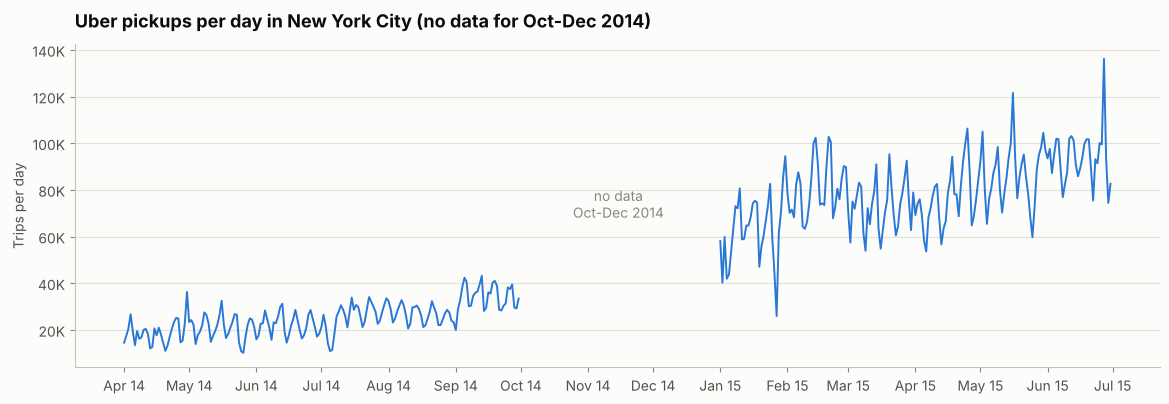

In [15]:
fig, ax = plt.subplots(figsize=(14, 4.2))
for period, part in daily.groupby("period"):
    ax.plot(part["date"], part["trips"], color=BLUE, lw=1.4)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(compact))
ax.yaxis.grid(True)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
ax.set_title("Uber pickups per day in New York City (no data for Oct-Dec 2014)")
ax.set_ylabel("Trips per day")
ax.text(pd.Timestamp("2014-11-15"), daily["trips"].max() * 0.5, "no data\nOct-Dec 2014", ha="center", color=MUTED)
save(fig, "01_daily_trips_2014_2015")

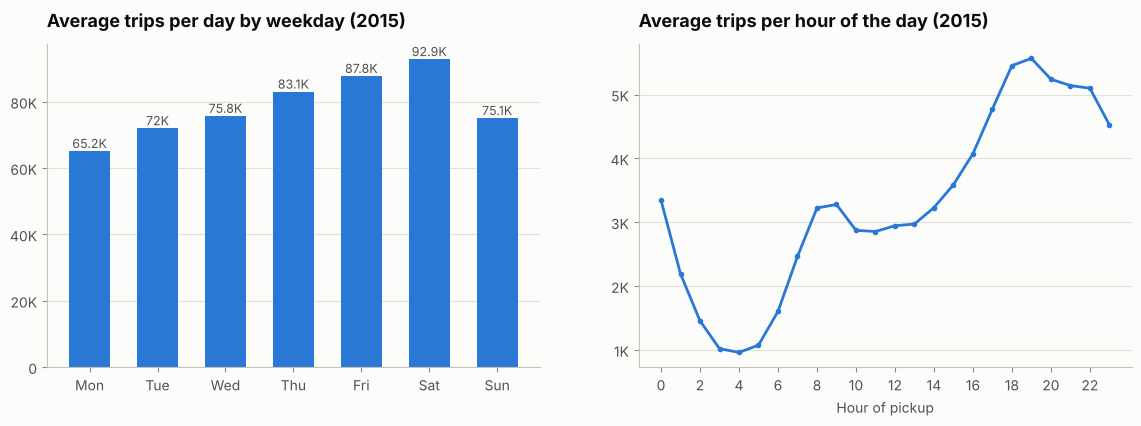

In [16]:
h15 = hourly[hourly["period"] == "2015 Jan-Jun"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
wd = d15.groupby("weekday", observed=True)["trips"].mean()
axes[0].bar(range(7), wd.values, color=BLUE, width=0.6)
axes[0].set_xticks(range(7), [w[:3] for w in wd.index])
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(compact))
axes[0].yaxis.grid(True)
axes[0].set_title("Average trips per day by weekday (2015)")
for i, v in enumerate(wd.values):
    axes[0].text(i, v, compact(v), ha="center", va="bottom", fontsize=9, color=INK_2)
hr = h15.groupby("hour")["trips"].mean()
axes[1].plot(hr.index, hr.values, color=BLUE, marker="o", ms=3)
axes[1].set_xticks(range(0, 24, 2))
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(compact))
axes[1].yaxis.grid(True)
axes[1].set_title("Average trips per hour of the day (2015)")
axes[1].set_xlabel("Hour of pickup")
save(fig, "02_weekday_and_hour_2015")

**First look:** demand grows steadily in both periods and is several times higher in 2015 than in 2014. Every week shows
the same rhythm (dips on Sundays/Mondays), and each day has a deep low around 4–5 am and a broad evening peak.

## 15. KPI calculations

In [17]:
dow15 = d15.groupby("weekday", observed=True)["trips"].mean()
hour15 = h15.groupby("hour")["trips"].mean()
zone_total = zone_daily.merge(zones, on="location_id")
area_tot = zone_total.groupby("service_area")["trips"].sum()
known = area_tot.drop("Unknown", errors="ignore").sum()
vehicle_days = foil["active_vehicles"].sum()
kpi = {
    "trips_total": int(daily["trips"].sum()),
    "trips_2014": int(d14["trips"].sum()), "trips_2015": int(d15["trips"].sum()),
    "days_2014": int(d14["date"].nunique()), "days_2015": int(d15["date"].nunique()),
    "avg_daily_trips_2014": d14["trips"].mean(), "avg_daily_trips_2015": d15["trips"].mean(),
    "median_daily_trips_2015": d15["trips"].median(),
    "peak_day_2014": f"{d14.loc[d14['trips'].idxmax(), 'date']:%Y-%m-%d}", "peak_day_2014_trips": int(d14["trips"].max()),
    "peak_day_2015": f"{d15.loc[d15['trips'].idxmax(), 'date']:%Y-%m-%d}", "peak_day_2015_trips": int(d15["trips"].max()),
    "lowest_day_2014": f"{d14.loc[d14['trips'].idxmin(), 'date']:%Y-%m-%d}", "lowest_day_2014_trips": int(d14["trips"].min()),
    "lowest_day_2015": f"{d15.loc[d15['trips'].idxmin(), 'date']:%Y-%m-%d}", "lowest_day_2015_trips": int(d15["trips"].min()),
    "busiest_weekday_2015": dow15.idxmax(), "busiest_weekday_2015_avg": dow15.max(),
    "quietest_weekday_2015": dow15.idxmin(), "quietest_weekday_2015_avg": dow15.min(),
    "weekend_avg_daily_2015": d15.loc[d15["is_weekend"], "trips"].mean(),
    "weekday_avg_daily_2015": d15.loc[~d15["is_weekend"], "trips"].mean(),
    "peak_hour_2015": int(hour15.idxmax()), "peak_hour_avg_trips_2015": hour15.max(),
    "quietest_hour_2015": int(hour15.idxmin()), "quietest_hour_avg_trips_2015": hour15.min(),
    "peak_to_trough_ratio_2015": hour15.max() / hour15.min(),
    "manhattan_share_2015": area_tot["Manhattan"] / known,
    "airport_share_2015": area_tot["Airports"] / known,
    "outside_manhattan_share_2015": 1 - area_tot["Manhattan"] / known,
    "unknown_zone_trips_2015": int(area_tot.get("Unknown", 0)),
    "foil_trips": int(foil["trips"].sum()), "foil_vehicle_days": int(vehicle_days),
    "trips_per_vehicle_day": foil["trips"].sum() / vehicle_days,
    "avg_active_vehicles_per_day": foil.groupby("date")["active_vehicles"].sum().mean(),
}
pd.Series(kpi, name="value").to_frame()

,value
trips_total,18804806
trips_2014,4534327
trips_2015,14270479
days_2014,183
days_2015,181
avg_daily_trips_2014,"24,777.74"
avg_daily_trips_2015,"78,842.43"
median_daily_trips_2015,"78,343.00"
peak_day_2014,2014-09-13
peak_day_2014_trips,43205


| KPI | Definition |
|---|---|
| Trips | Number of pickup records (one row = one trip, duplicates kept — see section 9) |
| Average trips per day | Trips ÷ number of days with data in the period |
| Peak hour | Hour of the day with the highest average number of pickups (2015) |
| Peak-to-trough ratio | Average trips in the peak hour ÷ average trips in the quietest hour |
| Manhattan / airport share | Share of 2015 pickups with a known taxi zone in Manhattan / at JFK, LaGuardia or Newark |
| Trips per active vehicle per day | FOIL trips ÷ FOIL active vehicles, summed over bases and days (productivity proxy, not driver utilization) |

## 16. Trend analysis — growth over time

In [18]:
monthly = (daily.groupby(["period", "month"]).agg(trips=("trips", "sum"), days=("date", "nunique")).reset_index())
monthly["avg_trips_per_day"] = monthly["trips"] / monthly["days"]
monthly["mom_growth_pct"] = monthly.groupby("period")["trips"].pct_change() * 100
monthly["mom_growth_per_day_pct"] = monthly.groupby("period")["avg_trips_per_day"].pct_change() * 100
display(monthly.round(1))

yoy = monthly.assign(m=monthly["month"].str[5:]).pivot_table(index="m", columns="period", values="trips", aggfunc="sum")
yoy = yoy.dropna()
yoy["growth_pct"] = (yoy["2015 Jan-Jun"] / yoy["2014 Apr-Sep"] - 1) * 100
yoy.loc["Apr-Jun"] = [yoy["2014 Apr-Sep"].sum(), yoy["2015 Jan-Jun"].sum(), (yoy["2015 Jan-Jun"].sum() / yoy["2014 Apr-Sep"].sum() - 1) * 100]
display(yoy.round(1))
mp = monthly.set_index("month")["avg_trips_per_day"]
kpi.update({
    "monthly_trips": monthly.set_index("month")["trips"].to_dict(),
    "monthly_avg_trips_per_day": mp.to_dict(),
    "yoy_growth_apr_jun_pct": yoy.loc["Apr-Jun", "growth_pct"],
    "yoy_multiple_apr_jun": yoy.loc["Apr-Jun", "2015 Jan-Jun"] / yoy.loc["Apr-Jun", "2014 Apr-Sep"],
    "yoy_growth_by_month_pct": yoy["growth_pct"].drop("Apr-Jun").rename(index={"04": "Apr", "05": "May", "06": "Jun"}).to_dict(),
    "growth_apr_sep_2014_per_day_pct": (mp["2014-09"] / mp["2014-04"] - 1) * 100,
    "growth_jan_jun_2015_per_day_pct": (mp["2015-06"] / mp["2015-01"] - 1) * 100,
})

,period,month,trips,days,avg_trips_per_day,mom_growth_pct,mom_growth_per_day_pct
0,2014 Apr-Sep,2014-04,564516,30,"18,817.20",NaN,NaN
1,2014 Apr-Sep,2014-05,652435,31,"21,046.30",15.60,11.80
2,2014 Apr-Sep,2014-06,663844,30,"22,128.10",1.70,5.10
3,2014 Apr-Sep,2014-07,796121,31,"25,681.30",19.90,16.10
4,2014 Apr-Sep,2014-08,829275,31,"26,750.80",4.20,4.20
5,2014 Apr-Sep,2014-09,1028136,30,"34,271.20",24.00,28.10
6,2015 Jan-Jun,2015-01,1953801,31,"63,025.80",NaN,NaN
7,2015 Jan-Jun,2015-02,2263620,28,"80,843.60",15.90,28.30
8,2015 Jan-Jun,2015-03,2259773,31,"72,895.90",-0.20,-9.80
9,2015 Jan-Jun,2015-04,2280837,30,"76,027.90",0.90,4.30


period,2014 Apr-Sep,2015 Jan-Jun,growth_pct
m,,,
04,"564,516.00","2,280,837.00",304.00
05,"652,435.00","2,695,553.00",313.20
06,"663,844.00","2,816,895.00",324.30
Apr-Jun,"1,880,795.00","7,793,285.00",314.40


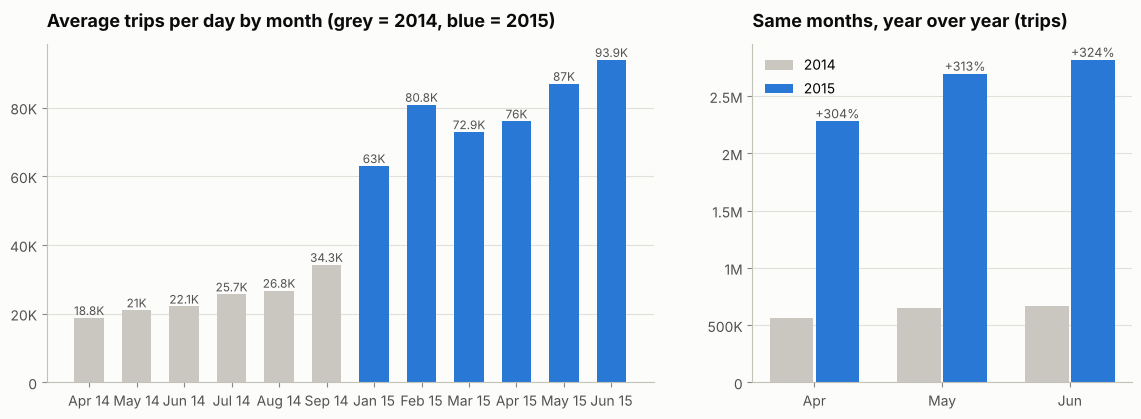

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
labels = [pd.Timestamp(m + "-01").strftime("%b %y") for m in monthly["month"]]
colors = [BLUE if p.startswith("2015") else LIGHT_GRAY for p in monthly["period"]]
ax.bar(range(len(monthly)), monthly["avg_trips_per_day"], color=colors, width=0.62)
ax.set_xticks(range(len(monthly)), labels)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(compact))
ax.yaxis.grid(True)
ax.set_title("Average trips per day by month (grey = 2014, blue = 2015)")
for i, v in enumerate(monthly["avg_trips_per_day"]):
    ax.text(i, v, compact(v), ha="center", va="bottom", fontsize=8.5, color=INK_2)
ax = axes[1]
y = yoy.drop("Apr-Jun")
x = np.arange(len(y))
ax.bar(x - 0.18, y["2014 Apr-Sep"], width=0.34, color=LIGHT_GRAY, label="2014")
ax.bar(x + 0.18, y["2015 Jan-Jun"], width=0.34, color=BLUE, label="2015")
ax.set_xticks(x, ["Apr", "May", "Jun"])
ax.yaxis.set_major_formatter(mticker.FuncFormatter(compact))
ax.yaxis.grid(True)
ax.legend(loc="upper left")
ax.set_title("Same months, year over year (trips)")
for i, g in enumerate(y["growth_pct"]):
    ax.text(i + 0.18, y["2015 Jan-Jun"].iloc[i], f"+{g:.0f}%", ha="center", va="bottom", fontsize=9, color=INK_2)
save(fig, "03_monthly_and_yoy_growth")

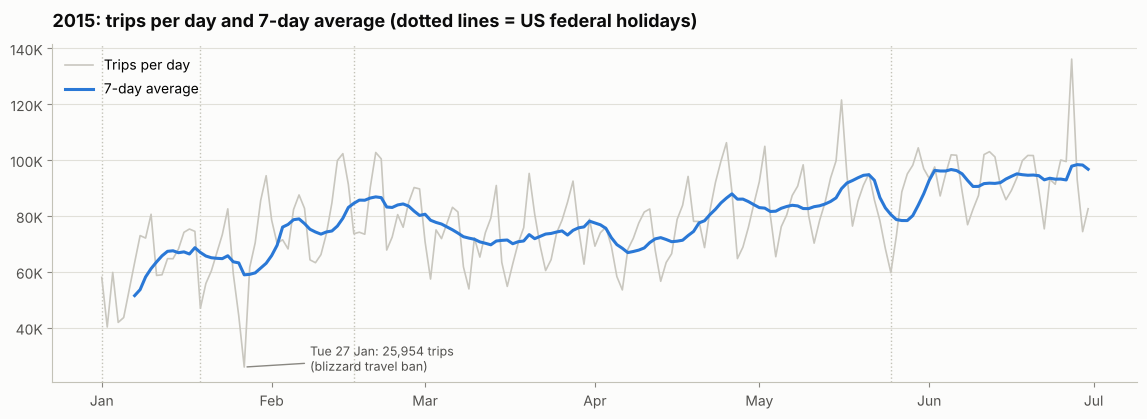

Full weeks: first 445,139 trips -> last 688,860 trips


In [20]:
s = d15.set_index("date")["trips"]
ma7 = s.rolling(7).mean()
fig, ax = plt.subplots(figsize=(14, 4.4))
ax.plot(s.index, s.values, color=LIGHT_GRAY, lw=1.2, label="Trips per day")
ax.plot(ma7.index, ma7.values, color=BLUE, lw=2.2, label="7-day average")
low = s.idxmin()
ax.annotate(f"{low:%a %d %b}: {s.min():,} trips\n(blizzard travel ban)", xy=(low, s.min()), xytext=(low + pd.Timedelta(days=12), s.min() * 0.95),
            arrowprops=dict(arrowstyle="-", color=MUTED), fontsize=9, color=INK_2)
for day in d15.loc[d15["is_holiday"], "date"]:
    ax.axvline(day, color=AXIS, lw=1, ls=":", zorder=0)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(compact))
ax.yaxis.grid(True)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.legend(loc="upper left")
ax.set_title("2015: trips per day and 7-day average (dotted lines = US federal holidays)")
save(fig, "04_daily_trend_2015")
weekly = s.resample("W-SUN").agg(["sum", "count"])
full_weeks = weekly[weekly["count"] == 7]["sum"]
kpi.update({"first_full_week_2015": f"{full_weeks.index[0] - pd.Timedelta(days=6):%Y-%m-%d}", "first_full_week_2015_trips": int(full_weeks.iloc[0]),
            "last_full_week_2015": f"{full_weeks.index[-1] - pd.Timedelta(days=6):%Y-%m-%d}", "last_full_week_2015_trips": int(full_weeks.iloc[-1]),
            "weekly_growth_first_to_last_pct": (full_weeks.iloc[-1] / full_weeks.iloc[0] - 1) * 100})
print(f"Full weeks: first {full_weeks.iloc[0]:,} trips -> last {full_weeks.iloc[-1]:,} trips")

**Reading the trend:** both periods grow month after month, and the same months were roughly 4.1× busier in
2015 than in 2014. The lowest day of 2015, Tuesday 27 January 2015, coincides with the January 2015 blizzard: New York City
banned non-emergency driving from 11 pm on 26 January until the morning of 27 January
([Brooklyn Eagle, 27 Jan 2015](https://brooklyneagle.com/articles/2015/01/27/mayor-cancels-school-in-advance-of-blizzard-of-2015/)).
The weather event is outside the dataset and is used only to explain the dip.

## 17. Segment analysis

### 17.1 Time of day, weekday, holidays

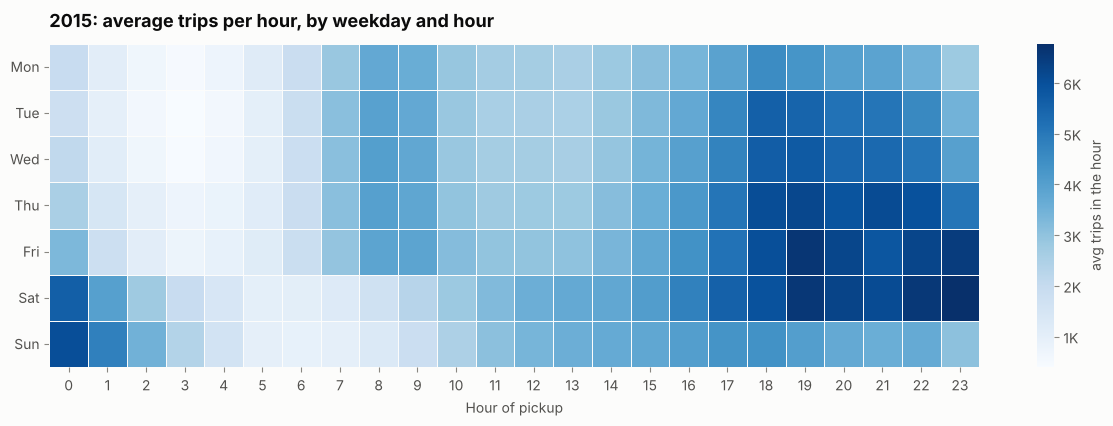

In [21]:
heat = h15.pivot_table(index="weekday", columns="hour", values="trips", aggfunc="mean", observed=True)
fig, ax = plt.subplots(figsize=(15, 4.2))
sns.heatmap(heat, cmap="Blues", linewidths=0.5, linecolor=SURFACE, cbar_kws={"label": "avg trips in the hour", "format": mticker.FuncFormatter(compact)}, ax=ax)
ax.set_yticklabels([w[:3] for w in heat.index], rotation=0)
ax.set_xlabel("Hour of pickup")
ax.set_ylabel("")
ax.set_title("2015: average trips per hour, by weekday and hour")
save(fig, "05_heatmap_weekday_hour_2015")

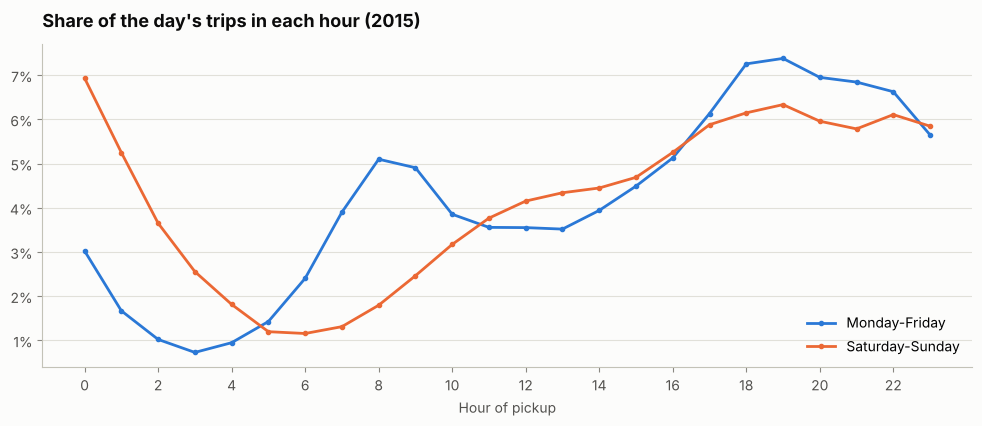

,Mon-Fri,Sat-Sun
time_band,,
Night (0-5),8.80,21.40
Morning peak (6-9),16.30,6.70
Midday (10-15),22.90,24.60
Evening peak (16-19),25.90,23.60
Late evening (20-23),26.10,23.70


In [22]:
profile = h15.groupby(["is_weekend", "hour"])["trips"].sum()
profile = profile / profile.groupby(level=0).transform("sum")
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(range(24), profile.loc[False].values, color=BLUE, marker="o", ms=3, label="Monday-Friday")
ax.plot(range(24), profile.loc[True].values, color=ORANGE, marker="o", ms=3, label="Saturday-Sunday")
ax.set_xticks(range(0, 24, 2))
pct_axis(ax, decimals=0)
ax.yaxis.grid(True)
ax.legend()
ax.set_xlabel("Hour of pickup")
ax.set_title("Share of the day's trips in each hour (2015)")
save(fig, "06_hourly_profile_weekday_weekend")

bands = h15.groupby(["is_weekend", "time_band"], observed=True)["trips"].sum().unstack(0)
bands = bands / bands.sum()
bands.columns = ["Mon-Fri", "Sat-Sun"]
display((bands * 100).round(1))
kpi.update({
    "night_share_weekday_2015": bands.loc["Night (0-5)", "Mon-Fri"], "night_share_weekend_2015": bands.loc["Night (0-5)", "Sat-Sun"],
    "evening_peak_share_weekday_2015": bands.loc["Evening peak (16-19)", "Mon-Fri"],
    "morning_peak_share_weekday_2015": bands.loc["Morning peak (6-9)", "Mon-Fri"],
    "morning_peak_share_weekend_2015": bands.loc["Morning peak (6-9)", "Sat-Sun"],
    "peak_hour_weekday_2015": int(profile.loc[False].idxmax()), "peak_hour_weekend_2015": int(profile.loc[True].idxmax()),
})

In [23]:
# "Normal" = the same weekday 1, 2 and 3 weeks before and after (a local baseline, so the strong growth trend
# does not distort the comparison). Holidays and the two blizzard days are excluded from every baseline.
names = USFederalHolidayCalendar().holidays(start="2014-01-01", end="2015-12-31", return_name=True)
special = {d: n for d, n in names.items() if d in set(daily["date"])}
special[pd.Timestamp("2015-01-26")] = "Blizzard: travel ban from 11 pm (external event)"
special[pd.Timestamp("2015-01-27")] = "Blizzard: travel ban until the morning (external event)"
trips_by_day = daily.set_index("date")["trips"]
rows = []
for day, name in sorted(special.items()):
    window = [day + pd.Timedelta(weeks=k) for k in (-3, -2, -1, 1, 2, 3)]
    base = trips_by_day.reindex([d for d in window if d not in special]).dropna()
    rows.append({"date": day, "special_day": name, "weekday": day.day_name(), "trips": trips_by_day[day],
                 "normal_same_weekday": base.mean(), "baseline_days": len(base)})
special_days = pd.DataFrame(rows)
special_days["vs_normal_pct"] = (special_days["trips"] / special_days["normal_same_weekday"] - 1) * 100
hol = special_days[~special_days["special_day"].str.startswith("Blizzard")]
kpi["holiday_effect_pct"] = hol.set_index(hol["date"].dt.strftime("%Y-%m-%d"))["vs_normal_pct"].to_dict()
kpi["avg_holiday_effect_pct"] = hol["vs_normal_pct"].mean()
kpi["blizzard_vs_normal_tuesday_pct"] = special_days.set_index("date").loc[pd.Timestamp("2015-01-27"), "vs_normal_pct"]
special_days.round(1)

/tmp/ipykernel_10460/579845623.py:20: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  special_days.round(1)


,date,special_day,weekday,trips,normal_same_weekday,baseline_days,vs_normal_pct
0,2014-05-26,Memorial Day,Monday,10202,"18,694.80",6,-45.40
1,2014-07-04,Independence Day,Friday,14148,"28,160.00",6,-49.80
2,2014-09-01,Labor Day,Monday,19961,"25,801.20",6,-22.60
3,2015-01-01,New Year's Day,Thursday,58045,"69,348.70",3,-16.30
4,2015-01-19,"Birthday of Martin Luther King, Jr.",Monday,47025,"59,042.00",4,-20.40
5,2015-01-26,Blizzard: travel ban from 11 pm (external event),Monday,44310,"59,042.00",4,-25.00
6,2015-01-27,Blizzard: travel ban until the morning (extern...,Tuesday,25954,"64,353.50",6,-59.70
7,2015-02-16,Washington's Birthday,Monday,73672,"63,474.60",5,16.10
8,2015-05-25,Memorial Day,Monday,59748,"78,071.00",6,-23.50


### 17.2 Geography — boroughs, zones and airports (2015)

service_area
Manhattan       72.67
Brooklyn        16.27
Queens           5.53
Airports         3.89
Bronx            1.54
Staten Island    0.05
Unknown          0.04
Name: share_%, dtype: float64

service_area
Airports         72.70
Bronx           124.50
Brooklyn         60.70
Manhattan        41.30
Queens           95.00
Staten Island   110.20
Name: growth in trips per day, Jan -> Jun 2015 (%), dtype: float64

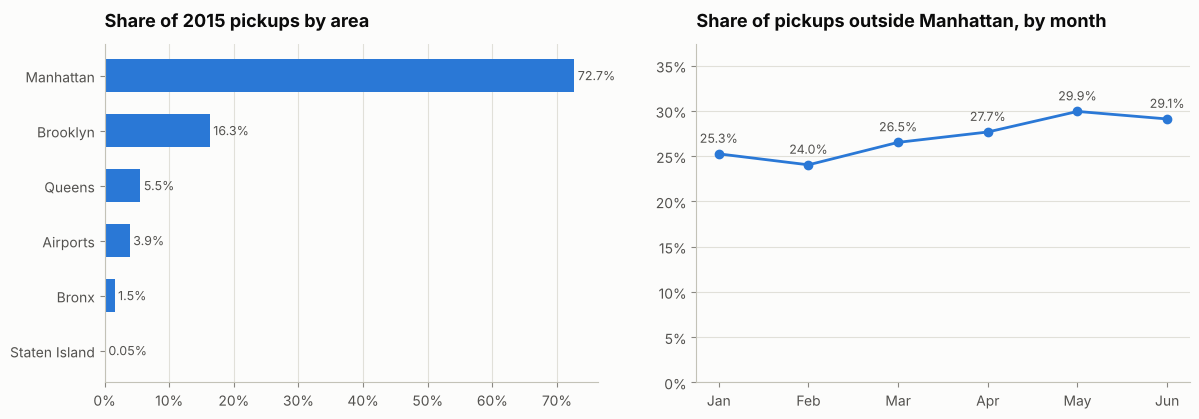

In [24]:
area_share = (area_tot / area_tot.sum()).sort_values(ascending=False)
zm = zone_total.assign(month=zone_total["date"].dt.strftime("%Y-%m"))
area_month = zm[zm["service_area"] != "Unknown"].pivot_table(index="month", columns="service_area", values="trips", aggfunc="sum")
outside_share = 1 - area_month["Manhattan"] / area_month.sum(axis=1)
days_in_month = d15.groupby("month")["date"].nunique()
area_growth = (area_month.div(days_in_month, axis=0).loc["2015-06"] / area_month.div(days_in_month, axis=0).loc["2015-01"] - 1) * 100
display((area_share * 100).round(2).rename("share_%"))
display(area_growth.round(1).rename("growth in trips per day, Jan -> Jun 2015 (%)"))
kpi.update({
    "area_share_2015": area_share.to_dict(),
    "outside_manhattan_share_jan_2015": outside_share.loc["2015-01"], "outside_manhattan_share_jun_2015": outside_share.loc["2015-06"],
    "area_growth_jan_jun_2015_pct": area_growth.to_dict(),
})
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
a = area_share.drop("Unknown", errors="ignore")
axes[0].barh(a.index[::-1], a.values[::-1], color=BLUE, height=0.6)
pct_axis(axes[0], axis="x")
axes[0].xaxis.grid(True)
axes[0].set_title("Share of 2015 pickups by area")
for i, v in enumerate(a.values[::-1]):
    axes[0].text(v, i, f" {v:.1%}" if v >= 0.01 else f" {v:.2%}", va="center", fontsize=9, color=INK_2)
axes[1].plot([pd.Timestamp(m + "-01").strftime("%b") for m in outside_share.index], outside_share.values, color=BLUE, marker="o")
pct_axis(axes[1], decimals=0)
axes[1].yaxis.grid(True)
axes[1].set_ylim(0, max(outside_share.max() * 1.25, 0.3))
axes[1].set_title("Share of pickups outside Manhattan, by month")
for x_, v in enumerate(outside_share.values):
    axes[1].annotate(f"{v:.1%}", (x_, v), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=9, color=INK_2)
save(fig, "07_areas_2015")

Zones without any Uber pickup in Jan-Jun 2015: [[103, 'Manhattan', "Governor's Island/Ellis Island/Liberty Island"], [104, 'Manhattan', "Governor's Island/Ellis Island/Liberty Island"], [199, 'Bronx', 'Rikers Island']]


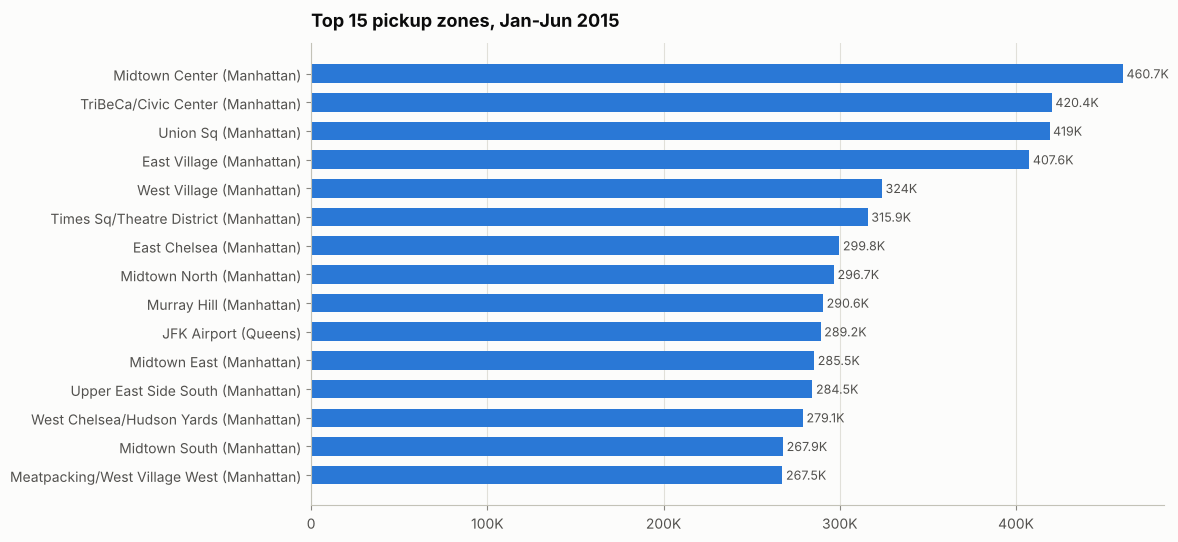

,location_id,zone,borough,trips,share,cum_share
0,161,Midtown Center,Manhattan,460732,0.03,0.03
1,231,TriBeCa/Civic Center,Manhattan,420356,0.03,0.06
2,234,Union Sq,Manhattan,419045,0.03,0.09
3,79,East Village,Manhattan,407591,0.03,0.12
4,249,West Village,Manhattan,323989,0.02,0.14
5,230,Times Sq/Theatre District,Manhattan,315919,0.02,0.16
6,68,East Chelsea,Manhattan,299781,0.02,0.19
7,163,Midtown North,Manhattan,296734,0.02,0.21
8,170,Murray Hill,Manhattan,290550,0.02,0.23
9,132,JFK Airport,Queens,289169,0.02,0.25


In [25]:
zt = (zone_total.groupby(["location_id", "zone", "borough"])["trips"].sum().sort_values(ascending=False).reset_index())
zt["share"] = zt["trips"] / zt["trips"].sum()
zt["cum_share"] = zt["share"].cumsum()
known_zones = zones[~zones["location_id"].isin([264, 265])]
no_pickups = known_zones[~known_zones["location_id"].isin(zt["location_id"])]
kpi.update({
    "zones_with_pickups": int(zt.loc[~zt["location_id"].isin([264, 265]), "location_id"].nunique()),
    "zones_total": int(len(known_zones)),
    "zones_without_pickups": no_pickups["zone"].tolist(),
    "zones_for_50pct": int((zt["cum_share"] < 0.5).sum() + 1), "zones_for_80pct": int((zt["cum_share"] < 0.8).sum() + 1),
    "top_zone": zt.loc[0, "zone"], "top_zone_borough": zt.loc[0, "borough"], "top_zone_share": zt.loc[0, "share"],
    "top10_zone_share": zt["share"].head(10).sum(),
    "top_zones": zt.head(10).set_index("zone")["trips"].to_dict(),
})
print("Zones without any Uber pickup in Jan-Jun 2015:", no_pickups[["location_id", "borough", "zone"]].values.tolist())
top = zt.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh([f"{z} ({b})" for z, b in zip(top["zone"], top["borough"])], top["trips"], color=BLUE, height=0.65)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(compact))
ax.xaxis.grid(True)
ax.set_title("Top 15 pickup zones, Jan-Jun 2015")
for i, v in enumerate(top["trips"]):
    ax.text(v, i, f" {compact(v)}", va="center", fontsize=9, color=INK_2)
save(fig, "08_top_zones_2015")
zt.head(15).round(4)

zone
JFK Airport          289169
LaGuardia Airport    266119
Newark Airport          105
Name: trips Jan-Jun 2015, dtype: int64

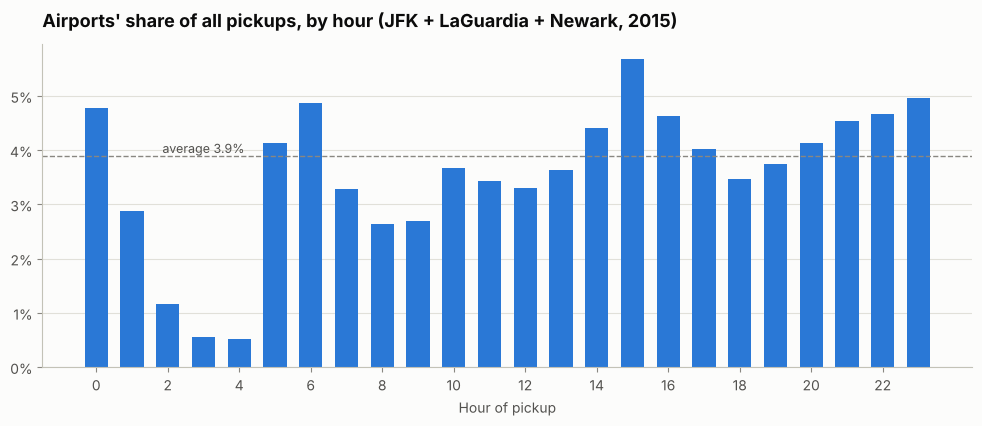

In [26]:
ah = area_hourly.pivot_table(index="hour", columns="service_area", values="trips", aggfunc="sum", observed=True)
airport_hour_share = ah["Airports"] / ah.sum(axis=1)
airports = zone_total[zone_total["is_airport"]].groupby("zone")["trips"].sum().sort_values(ascending=False)
kpi.update({"airport_trips_2015": airports.to_dict(), "airport_trips_per_day_2015": airports.sum() / kpi["days_2015"],
            "airport_peak_share_hour": int(airport_hour_share.idxmax()), "airport_peak_share": airport_hour_share.max(),
            "airport_low_share_hour": int(airport_hour_share.idxmin()), "airport_low_share": airport_hour_share.min(),
            "airport_share_by_hour": airport_hour_share.to_dict(),
            "airport_peak_volume_hour": int(ah["Airports"].idxmax()), "airport_peak_volume_trips": int(ah["Airports"].max())})
display(airports.rename("trips Jan-Jun 2015"))
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.bar(airport_hour_share.index, airport_hour_share.values, color=BLUE, width=0.65)
ax.axhline(kpi["airport_share_2015"], color=MUTED, lw=1, ls="--")
ax.text(3, kpi["airport_share_2015"], f"average {kpi['airport_share_2015']:.1%}", va="bottom", ha="center", fontsize=9, color=INK_2)
pct_axis(ax, decimals=0)
ax.yaxis.grid(True)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hour of pickup")
ax.set_title("Airports' share of all pickups, by hour (JFK + LaGuardia + Newark, 2015)")
save(fig, "09_airport_share_by_hour")

### 17.3 Dispatching bases

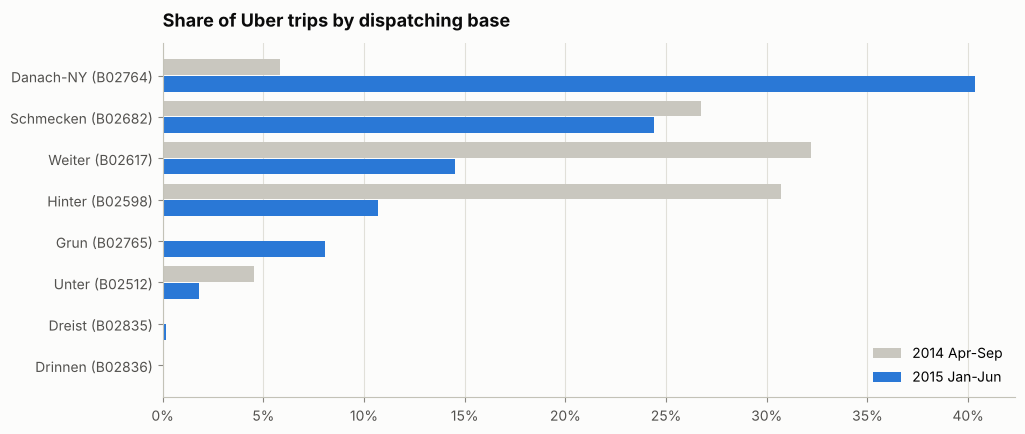

Dispatching base = affiliated base for 74.4% of 2015 trips


period,2014 Apr-Sep,2015 Jan-Jun
base_name,,
Drinnen,0.00,0.01
Dreist,0.00,0.19
Unter,4.54,1.79
Grun,0.00,8.08
Hinter,30.72,10.70
Weiter,32.17,14.50
Schmecken,26.75,24.42
Danach-NY,5.82,40.32


In [27]:
bp = base_daily.assign(period=np.where(base_daily["date"].dt.year == 2014, "2014 Apr-Sep", "2015 Jan-Jun"))
bshare = bp.groupby(["period", "base_name"])["trips"].sum().unstack(0).fillna(0)
bshare = bshare / bshare.sum()
bshare = bshare.sort_values("2015 Jan-Jun")
pairs = t15.groupby(["dispatching_base", "affiliated_base"], observed=True).size().rename("trips").reset_index()
same = pairs[pairs["dispatching_base"].astype(str) == pairs["affiliated_base"].astype(str)]["trips"].sum() / pairs["trips"].sum()
kpi.update({"base_share_2014": bshare["2014 Apr-Sep"][bshare["2014 Apr-Sep"] > 0].to_dict(), "base_share_2015": bshare["2015 Jan-Jun"].to_dict(),
            "dispatch_equals_affiliated_share": same, "affiliated_bases_2015": int(t15["affiliated_base"].nunique())})
fig, ax = plt.subplots(figsize=(11, 4.6))
y = np.arange(len(bshare))
ax.barh(y + 0.2, bshare["2014 Apr-Sep"], height=0.38, color=LIGHT_GRAY, label="2014 Apr-Sep")
ax.barh(y - 0.2, bshare["2015 Jan-Jun"], height=0.38, color=BLUE, label="2015 Jan-Jun")
CODE_OF = {v: k for k, v in BASE_NAMES.items()}
ax.set_yticks(y, [f"{n} ({CODE_OF[n]})" for n in bshare.index])
pct_axis(ax, axis="x")
ax.xaxis.grid(True)
ax.legend(loc="lower right")
ax.set_title("Share of Uber trips by dispatching base")
save(fig, "10_base_share")
print(f"Dispatching base = affiliated base for {same:.1%} of 2015 trips")
(bshare * 100).round(2)

### 17.4 Supply — active vehicles and trips per vehicle (FOIL, Jan–Feb 2015)

`active_vehicles` is the number of vehicles that worked for a base on a given day. Trips per active vehicle per day is a
**productivity proxy**: it does not show how many hours each driver was online, so it is *not* driver utilization.

,base_code,base_name,avg_active_vehicles,trips,vehicle_days,trips_per_vehicle_day
3,B02682,Schmecken,"1,210.69",662509,71431,9.27
1,B02598,Hinter,994.12,540791,58653,9.22
2,B02617,Weiter,"1,351.83",725025,79758,9.09
4,B02764,Danach-NY,"3,682.88",1914449,217290,8.81
5,B02765,Grun,382.63,193670,22575,8.58
0,B02512,Unter,222.46,93786,13125,7.15


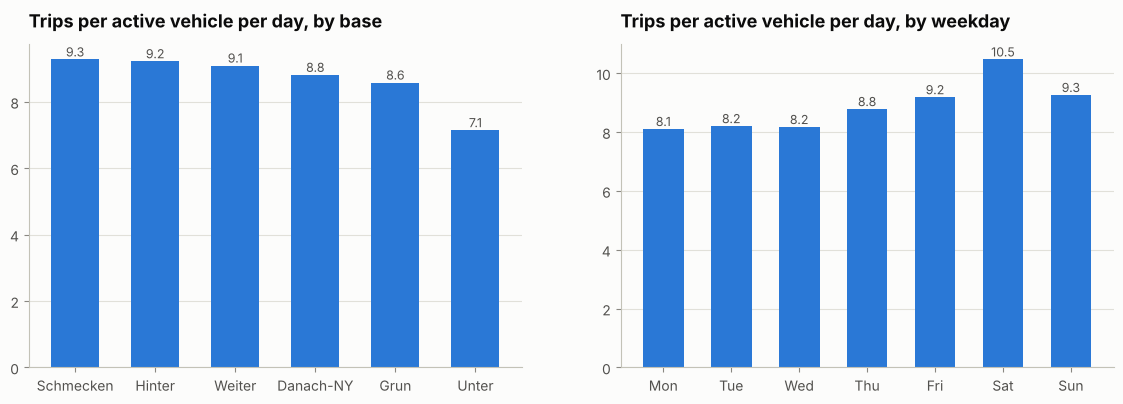

Fleet: 7,350 active vehicles per day in the first full week -> 8,494 in the last full week


In [28]:
fb = foil.groupby(["base_code", "base_name"]).agg(avg_active_vehicles=("active_vehicles", "mean"), trips=("trips", "sum"),
                                                  vehicle_days=("active_vehicles", "sum")).reset_index()
fb["trips_per_vehicle_day"] = fb["trips"] / fb["vehicle_days"]
fb = fb.sort_values("trips_per_vehicle_day", ascending=False)
fw = foil.assign(weekday=pd.Categorical(foil["date"].dt.day_name(), categories=WEEKDAYS, ordered=True)) \
         .groupby("weekday", observed=True)[["trips", "active_vehicles"]].sum()
fw["trips_per_vehicle_day"] = fw["trips"] / fw["active_vehicles"]
fleet = foil.groupby("date")[["active_vehicles", "trips"]].sum()
fleet_week = fleet["active_vehicles"].resample("W-SUN").agg(["mean", "count"])
fleet_week = fleet_week[fleet_week["count"] == 7]["mean"]          # full Monday-Sunday weeks only
wk = foil["date"].dt.dayofweek >= 5
kpi.update({
    "base_trips_per_vehicle": fb.set_index("base_name")["trips_per_vehicle_day"].to_dict(),
    "base_avg_active_vehicles": fb.set_index("base_name")["avg_active_vehicles"].to_dict(),
    "trips_per_vehicle_weekend": foil.loc[wk, "trips"].sum() / foil.loc[wk, "active_vehicles"].sum(),
    "trips_per_vehicle_weekday": foil.loc[~wk, "trips"].sum() / foil.loc[~wk, "active_vehicles"].sum(),
    "weekday_trips_per_vehicle": fw["trips_per_vehicle_day"].to_dict(),
    "fleet_first_full_week": f"{fleet_week.index[0] - pd.Timedelta(days=6):%Y-%m-%d}", "fleet_first_week_avg": fleet_week.iloc[0],
    "fleet_last_full_week": f"{fleet_week.index[-1] - pd.Timedelta(days=6):%Y-%m-%d}", "fleet_last_week_avg": fleet_week.iloc[-1],
    "fleet_growth_pct": (fleet_week.iloc[-1] / fleet_week.iloc[0] - 1) * 100,
    "foil_vs_pickup_rows_pct": dup_validation["foil_vs_rows_incl_dup_pct"],
})
display(fb.round(2))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].bar(fb["base_name"], fb["trips_per_vehicle_day"], color=BLUE, width=0.6)
axes[0].yaxis.grid(True)
axes[0].set_title("Trips per active vehicle per day, by base")
for i, v in enumerate(fb["trips_per_vehicle_day"]):
    axes[0].text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=9, color=INK_2)
axes[1].bar([w[:3] for w in fw.index], fw["trips_per_vehicle_day"], color=BLUE, width=0.6)
axes[1].yaxis.grid(True)
axes[1].set_title("Trips per active vehicle per day, by weekday")
for i, v in enumerate(fw["trips_per_vehicle_day"]):
    axes[1].text(i, v, f"{v:.1f}", ha="center", va="bottom", fontsize=9, color=INK_2)
save(fig, "11_trips_per_vehicle")
print(f"Fleet: {fleet_week.iloc[0]:,.0f} active vehicles per day in the first full week -> "
      f"{fleet_week.iloc[-1]:,.0f} in the last full week")

### 17.5 Market context — taxis, Lyft and other car services

company,Uber,Lyft,Yellow Taxis
date,,,
Jul 2014,"25,681.00",137.00,"418,388.00"
Aug 2014,"26,751.00","4,756.00","405,144.00"
Sep 2014,"34,271.00","3,867.00","441,307.00"


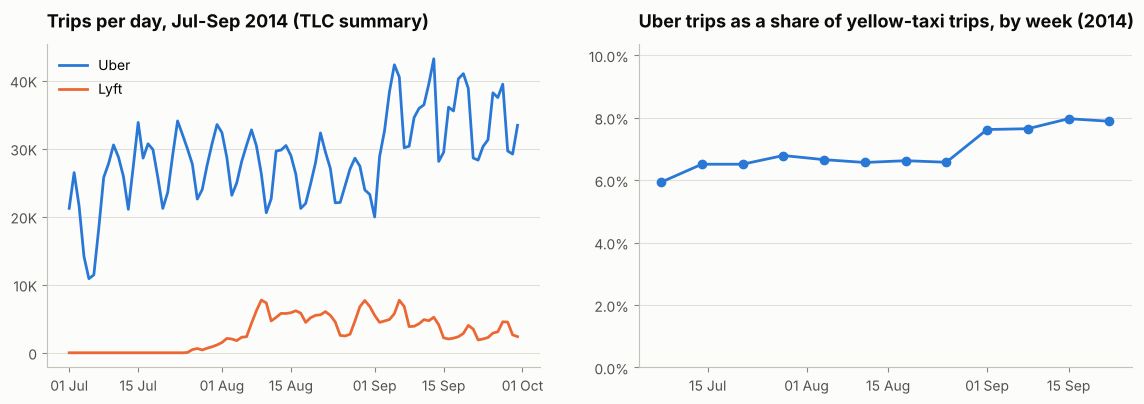

Uber trips per day as a share of yellow-taxi trips: 6.1% (Jul 2014) -> 7.8% (Sep 2014)


In [29]:
m = tlc.pivot(index="date", columns="company", values="trips")
mm = m.resample("MS").mean()
lyft_start = m.index[m["Lyft"] > 0][0]
uber_vs_yellow = mm["Uber"] / mm["Yellow Taxis"]
display(mm[["Uber", "Lyft", "Yellow Taxis"]].round(0).rename(index=lambda d: d.strftime("%b %Y")))
weekly_share = (m["Uber"].resample("W-SUN").sum() / m["Yellow Taxis"].resample("W-SUN").sum())
weekly_share = weekly_share[m["Uber"].resample("W-SUN").count() == 7]          # full weeks only
fhv_cov = fhv_daily.assign(month=fhv_daily["date"].dt.strftime("%Y-%m")).groupby("month")["bases_reporting"].mean()
kpi.update({
    "uber_avg_daily_jul_2014": mm["Uber"].iloc[0], "uber_avg_daily_sep_2014": mm["Uber"].iloc[-1],
    "yellow_avg_daily_jul_2014": mm["Yellow Taxis"].iloc[0], "yellow_avg_daily_sep_2014": mm["Yellow Taxis"].iloc[-1],
    "uber_vs_yellow_jul_2014": uber_vs_yellow.iloc[0], "uber_vs_yellow_sep_2014": uber_vs_yellow.iloc[-1],
    "lyft_first_day": f"{lyft_start:%Y-%m-%d}", "lyft_avg_daily_sep_2014": mm["Lyft"].iloc[-1],
    "uber_to_lyft_sep_2014": mm["Uber"].iloc[-1] / mm["Lyft"].iloc[-1],
    "fhv_report_bases_per_day_by_month": fhv_cov.to_dict(),
})
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(m.index, m["Uber"], color=BLUE, label="Uber")
axes[0].plot(m.index, m["Lyft"], color=ORANGE, label="Lyft")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(compact))
axes[0].yaxis.grid(True)
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axes[0].legend(loc="upper left")
axes[0].set_title("Trips per day, Jul-Sep 2014 (TLC summary)")
axes[1].plot(weekly_share.index - pd.Timedelta(days=6), weekly_share.values, color=BLUE, marker="o")
pct_axis(axes[1], decimals=1)
axes[1].set_ylim(0, weekly_share.max() * 1.3)
axes[1].yaxis.grid(True)
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axes[1].set_title("Uber trips as a share of yellow-taxi trips, by week (2014)")
save(fig, "12_market_context")
print(f"Uber trips per day as a share of yellow-taxi trips: {uber_vs_yellow.iloc[0]:.1%} (Jul 2014) -> {uber_vs_yellow.iloc[-1]:.1%} (Sep 2014)")

The TLC summary covers the same 92 days for every company, so these comparisons are like for like. The TLC base report
for 2015 (other car services) is **not** used for market share: the number of bases reporting per day changes from about
59 in January to 202 in May and 5 in August, so any share computed from it would mostly
reflect reporting coverage, not demand.

## 18. Correlation analysis — how supply and demand move together

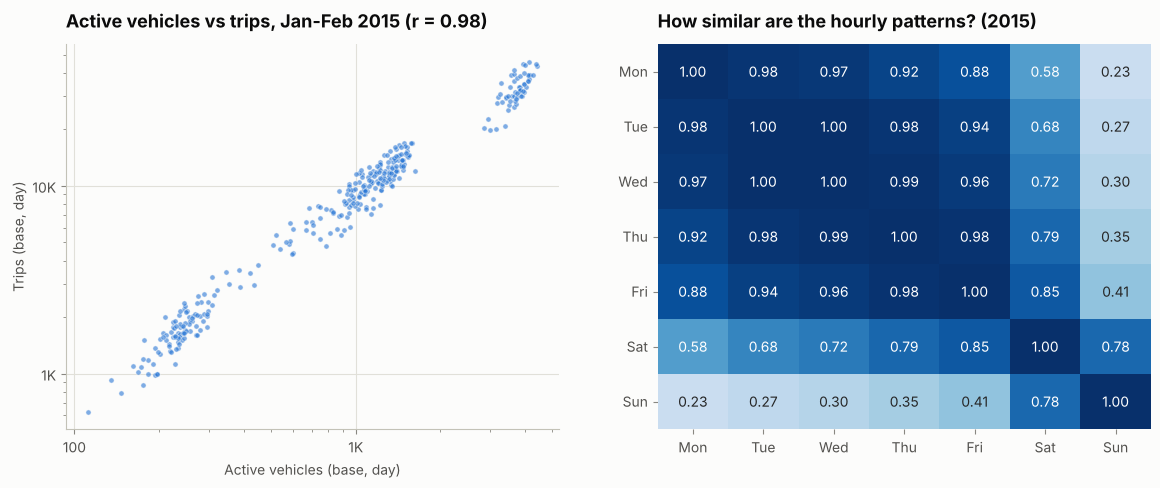

base_name
Danach-NY   0.79
Grun        0.98
Hinter      0.85
Schmecken   0.89
Unter       0.87
Weiter      0.82
Name: r (vehicles vs trips, daily), dtype: float64

In [30]:
r_all = foil["active_vehicles"].corr(foil["trips"])
r_base = foil.groupby("base_name").apply(lambda g: g["active_vehicles"].corr(g["trips"]), include_groups=False)
dshare = h15.groupby(["weekday", "hour"], observed=True)["trips"].sum()
dshare = (dshare / dshare.groupby(level=0, observed=True).transform("sum")).unstack(0)
prof_corr = dshare.corr()
kpi.update({"corr_vehicles_trips": r_all, "corr_vehicles_trips_by_base": r_base.to_dict(),
            "corr_profile_mon_sat": prof_corr.loc["Monday", "Saturday"], "corr_profile_tue_thu": prof_corr.loc["Tuesday", "Thursday"]})
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(foil["active_vehicles"], foil["trips"], s=14, color=BLUE, alpha=0.6, edgecolor=SURFACE, linewidth=0.5)
axes[0].set_xscale("log")
axes[0].set_yscale("log")
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(compact))
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(compact))
axes[0].grid(True, which="major")
axes[0].set_xlabel("Active vehicles (base, day)")
axes[0].set_ylabel("Trips (base, day)")
axes[0].set_title(f"Active vehicles vs trips, Jan-Feb 2015 (r = {r_all:.2f})")
sns.heatmap(prof_corr, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=axes[1],
            xticklabels=[w[:3] for w in prof_corr.columns], yticklabels=[w[:3] for w in prof_corr.index])
axes[1].tick_params(axis="y", rotation=0)
axes[1].set_xlabel("")
axes[1].set_ylabel("")
axes[1].set_title("How similar are the hourly patterns? (2015)")
save(fig, "13_correlation")
r_base.round(3).rename("r (vehicles vs trips, daily)")

Vehicles and trips move almost one-for-one (more vehicles on the road ↔ more trips), but correlation does not show the
direction: more drivers can create more trips, and more demand attracts more drivers. Monday–Friday share one hourly
pattern; Saturday and Sunday each have their own, so they need separate shift plans.

## 19. Visualisations — where Uber picked up passengers (2014)

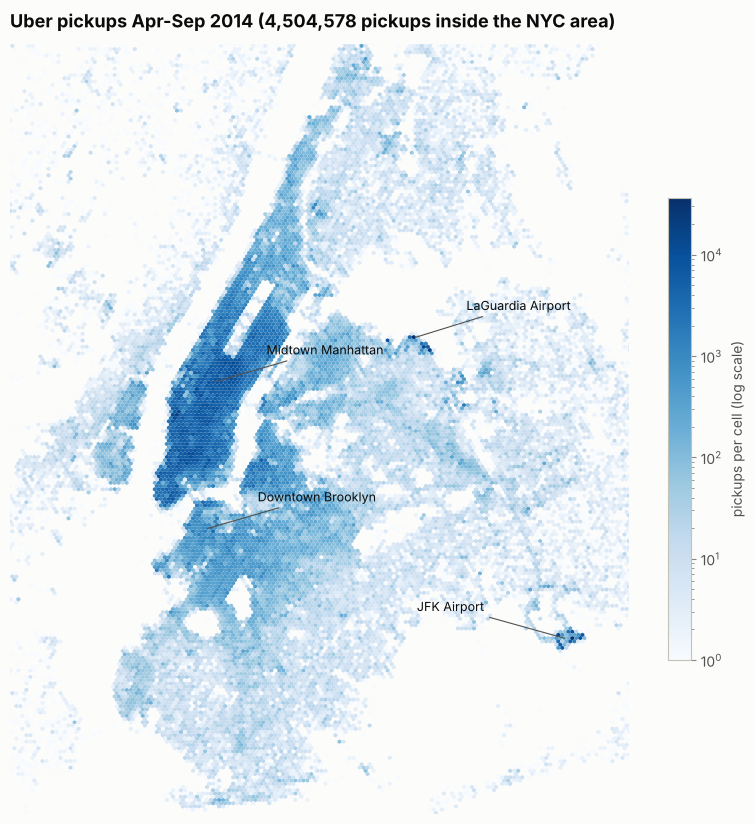

In [31]:
inside = t14[t14["in_nyc_box"]]
fig, ax = plt.subplots(figsize=(10, 10))
hb = ax.hexbin(inside["lon"], inside["lat"], gridsize=260, bins="log", cmap="Blues", mincnt=1, linewidths=0)
ax.set_aspect(1 / np.cos(np.radians(40.7)))
ax.set_xlim(-74.10, -73.75)
ax.set_ylim(40.57, 40.90)
ax.set_xticks([])
ax.set_yticks([])
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
for label, (lat, lon) in {"Midtown Manhattan": (40.755, -73.985), "JFK Airport": (40.645, -73.785),
                          "LaGuardia Airport": (40.774, -73.872), "Downtown Brooklyn": (40.692, -73.990)}.items():
    dx = -0.085 if label == "JFK Airport" else 0.03
    ax.annotate(label, xy=(lon, lat), xytext=(lon + dx, lat + 0.012), fontsize=9, color=INK,
                arrowprops=dict(arrowstyle="-", color=INK_2, lw=0.8))
cb = fig.colorbar(hb, ax=ax, shrink=0.6)
cb.set_label("pickups per cell (log scale)")
ax.set_title(f"Uber pickups Apr-Sep 2014 ({len(inside):,} pickups inside the NYC area)")
save(fig, "14_pickup_density_2014")

### Save the KPI summary (source of every number in the README and reports)

In [32]:
def py(v):
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, (np.floating, float)):
        return round(float(v), 6)
    if isinstance(v, (np.bool_,)):
        return bool(v)
    if isinstance(v, dict):
        return {str(k): py(x) for k, x in v.items()}
    if isinstance(v, (list, tuple)):
        return [py(x) for x in v]
    return v


kpi.update({
    "duplicates_2014": n_dup14, "duplicates_2015": n_dup15, "affiliated_missing_2015": int(missing_report.query("column == 'Affiliated_base_num'")["missing"].sum()),
    "outside_nyc_2014": int(len(t14) - len(inside)), "unknown_zone_2015": int(unknown_zone),
    "tlc_days_validated": dup_validation["tlc_days_matching_with_duplicates"], "tlc_days_total": int(len(test1)),
    "foil_vs_rows_excl_dup_pct": dup_validation["foil_vs_rows_excl_dup_pct"],
    "dup_share_jan_feb_2015_pct": dup_validation["dup_share_jan_feb_pct"], "dup_share_mar_jun_2015_pct": dup_validation["dup_share_mar_jun_pct"],
    "seconds_share_jan_feb_2015_pct": dup_validation["seconds_share_jan_feb_pct"], "seconds_share_mar_jun_2015_pct": dup_validation["seconds_share_mar_jun_pct"],
    "yoy_multiple_if_2015_overstated": kpi["yoy_multiple_apr_jun"] * (1 - dup_validation["dup_share_jan_feb_pct"] / 100),
    "first_date_2014": f"{d14['date'].min():%Y-%m-%d}", "last_date_2014": f"{d14['date'].max():%Y-%m-%d}",
    "first_date_2015": f"{d15['date'].min():%Y-%m-%d}", "last_date_2015": f"{d15['date'].max():%Y-%m-%d}",
    "other_fhv_bases": int(fhv["base_number"].nunique()),
})
summary = {k: py(v) for k, v in kpi.items()}
(REPORTS / "kpi_summary.json").write_text(json.dumps(summary, indent=2, default=str))
print(f"Saved {len(summary)} values to reports/kpi_summary.json")

Saved 127 values to reports/kpi_summary.json


## 20. Key findings

1. **Demand quadrupled in one year.** Uber pickups in April–June 2015 were **4.1×** the April–June 2014 level
   (**+314.4%**): April +304%, May +313%, June +324%. Even if 2015 includes about 1.8% double records
   (section 9), the multiple stays about 4.1×.
2. **Growth continued inside each period.** Average trips per day rose +82.1% from April to September 2014 and
   +49.0% from January to June 2015, reaching 93,896 trips per day in June 2015.
3. **A stable weekly rhythm.** Saturday is the busiest day of the week in 2015 (92,868 trips on average)
   and Monday the quietest (65,164). The busiest single day was Saturday 27 June 2015 (136,193 trips).
4. **Evening peak, early-morning trough.** The busiest hour is 7–8 pm (5,566 trips on average) —
   **5.8× the quietest hour** (4–5 am). On weekdays the 4–8 pm window carries 25.9% of the day's trips.
5. **Weekend nights are a different market.** On Saturdays and Sundays 21.4% of trips start between midnight
   and 6 am (weekdays: 8.8%) and the busiest weekend hour is 12–1 am; the 6–10 am commute is
   16.3% of weekday trips but only 6.7% at weekends.
6. **Holidays and weather cut demand.** Compared with the same weekday one to three weeks before and after, federal
   holidays averaged -23% (Memorial Day 2014 -45%, Independence Day 2014 -50%; the
   exception was Presidents' Day 2015 at +16%). The blizzard
   day Tuesday 27 January 2015 had 25,954 trips — -60% versus a normal Tuesday.
7. **Manhattan dominates, the outer boroughs grow faster.** Manhattan had 72.7% of 2015 pickups, but the share
   outside Manhattan rose from 25.3% in January to 29.1% in June: trips per day grew +124% in the
   Bronx, +95% in Queens and +61% in Brooklyn, versus +41% in Manhattan.
8. **Demand is concentrated.** 25 of the 260 zones with pickups produce half of all trips, and the
   top zone, Midtown Center (Manhattan), alone has 3.2%. Only 3 zones had no pickup at all
   (island zones: Governor's Island/Ellis Island/Liberty Island (2 zone ids), Rikers Island).
9. **Airports.** JFK (289,169 trips) and LaGuardia (266,119) generate 3.9% of pickups — 3,068
   per day; Newark had only 105 pickups. Most airport pickups happen at 10–11 pm, but the airports' *share* of
   all pickups is highest at 3–4 pm (5.7%), when the city is quieter, and lowest at
   4–5 am (0.5%).
10. **Dispatch concentrated in one base.** Danach-NY (B02764) dispatched 40.3% of 2015 trips, up from
    5.8% in 2014.
11. **About 8.9 trips per active vehicle per day.** In January–February 2015 an average of 7,845 vehicles were
    active per day, and the fleet grew +15.6% between the first and last full week. Productivity ranged from
    7.1 to 9.3 trips per vehicle per day across bases (weekends 9.9, weekdays 8.5).
12. **Uber was gaining on taxis and far ahead of Lyft.** Uber's daily trips equalled 6.1% of yellow-taxi
    trips in July 2014 and 7.8% in September. Lyft started on 25 July 2014 and averaged 3,867 trips
    per day in September 2014 — Uber had 8.9× as many.

## 21. Business recommendations

| # | Recommendation | Based on finding |
|---|---|---|
| 1 | **Plan driver supply around the 4–8 pm peak and Friday/Saturday nights** — schedule shifts and peak-hour incentives there, and avoid paying incentives in the 3–6 am trough. | 4, 5 |
| 2 | **Recruit ahead of growth.** Trips per day grew +49.0% in five months; driver onboarding and vehicle supply must grow at the same pace to keep waiting times down. | 1, 2, 11 |
| 3 | **Airport playbook** — position drivers near JFK and LaGuardia for the afternoon and late-evening airport peaks, and manage airport queues separately from the city. | 9 |
| 4 | **Grow outside Manhattan** — targeted driver incentives and marketing in Brooklyn, Queens and the Bronx, where demand grows fastest. | 7 |
| 5 | **Holiday and severe-weather playbooks** — forecast lower demand on federal holidays and storm days and avoid paying peak incentives on those days. | 6 |
| 6 | **Track trips per active vehicle by base every week** and investigate bases that stay well below the average. | 11 |
| 7 | **Collect the missing data** — fares, trip duration and distance, driver online hours, cancellations and waiting times — to measure true utilization, revenue and service level. | Limitations |

**Limitations:** pickup records only (no fares, distance, duration, drop-off, cancellations or driver hours); 2014 and
2015 cover different months; 2015 counts may include about 1.8% double records (section 9); the FOIL supply file
covers only January–February 2015; the TLC base report for other car services has changing coverage, so Uber's share of
the car-service market is not calculated.